# **Problem Statement**

## Context

Business communities in the United States are facing high demand for human resources, but one of the constant challenges is identifying and attracting the right talent, which is perhaps the most important element in remaining competitive. Companies in the United States look for hard-working, talented, and qualified individuals both locally and abroad.

The Immigration and Nationality Act (INA) of the US permits foreign workers to come to the United States to work on either a temporary or permanent basis. The act also protects US workers against adverse impacts on their wages or working conditions by ensuring US employers' compliance with statutory requirements when they hire foreign workers to fill workforce shortages. The immigration programs are administered by the Office of Foreign Labor Certification (OFLC).

OFLC processes job certification applications for employers seeking to bring foreign workers into the United States and grants certifications in cases where employers can demonstrate that there are not sufficient US workers available to perform the work at wages that meet or exceed the wage paid for the occupation in the area of intended employment.

## Objective

In FY 2016, the OFLC processed 775,979 employer applications for 1,699,957 positions for temporary and permanent labor certifications, a nine percent increase over the previous year. Reviewing every case is becoming a tedious task as the number of applicants increases every year.

The growing number of applicants calls for a machine learning based solution that can help shortlist candidates with higher chances of visa approval. OFLC has hired the firm EasyVisa for data-driven solutions. As a data scientist at EasyVisa, you must analyze the data provided and, with the help of a classification model:

1. Facilitate the process of visa approvals.
2. Recommend a suitable profile for applicants whose visa should be certified or denied, based on the drivers that significantly influence the case status.

## Data Description

The data contains attributes of the employee and the employer. The detailed data dictionary is given below.

* **case_id**: ID of each visa application
* **continent**: Information on the continent of the employee
* **education_of_employee**: Information on the education of the employee
* **has_job_experience**: Does the employee have any job experience? Y = Yes; N = No
* **requires_job_training**: Does the employee require any job training? Y = Yes; N = No
* **no_of_employees**: Number of employees in the employer's company
* **yr_of_estab**: Year in which the employer's company was established
* **region_of_employment**: Information on the foreign worker's intended region of employment in the US
* **prevailing_wage**: Average wage paid to similarly employed workers in a specific occupation in the area of intended employment. The purpose of the prevailing wage is to ensure that the foreign worker is not underpaid compared to other workers offering the same or similar service in the same area of employment
* **unit_of_wage**: Unit of prevailing wage. Values include Hourly, Weekly, Monthly, and Yearly
* **full_time_position**: Is the position of work full-time? Y = Full-Time Position; N = Part-Time Position
* **case_status**: Flag indicating whether the visa was certified or denied

# **Importing necessary libraries**

In [1]:
# Libraries to help with reading and manipulating data
import numpy as np
import pandas as pd

# Library to split data
from sklearn.model_selection import train_test_split

# To scale the data using z-score
from sklearn.preprocessing import StandardScaler

# libraries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Removes the limit for the number of displayed columns
pd.set_option("display.max_columns", None)
# Sets the limit for the number of displayed rows
pd.set_option("display.max_rows", 100)

# Classification algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Libraries to get different metric scores
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
)

# To ignore unnecessary warnings
import warnings
warnings.filterwarnings("ignore")

# **Loading the dataset**

In [2]:
# reading the dataset
visa = pd.read_csv("EasyVisa.csv")

In [3]:
# copying data to another variable to avoid any changes to original data
data = visa.copy()

# **Overview of the Dataset**

## View the first and last 5 rows of the dataset

In [4]:
# First 5 rows of the data
data.head()

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,EZYV01,Asia,High School,N,N,14513,2007,West,592.2029,Hour,Y,Denied
1,EZYV02,Asia,Master's,Y,N,2412,2002,Northeast,83425.6500,Year,Y,Certified
2,EZYV03,Asia,Bachelor's,N,Y,44444,2008,West,122996.8600,Year,Y,Denied
3,EZYV04,Asia,Bachelor's,N,N,98,1897,West,83434.0300,Year,Y,Denied
4,EZYV05,Africa,Master's,Y,N,1082,2005,South,149907.3900,Year,Y,Certified


In [5]:
# Last 5 rows of the data
data.tail()

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
25475,EZYV25476,Asia,Bachelor's,Y,Y,2601,2008,South,77092.57,Year,Y,Certified
25476,EZYV25477,Asia,High School,Y,N,3274,2006,Northeast,279174.79,Year,Y,Certified
25477,EZYV25478,Asia,Master's,Y,N,1121,1910,South,146298.85,Year,N,Certified
25478,EZYV25479,Asia,Master's,Y,Y,1918,1887,West,86154.77,Year,Y,Certified
25479,EZYV25480,Asia,Bachelor's,Y,N,3195,1960,Midwest,70876.91,Year,Y,Certified


## Understand the shape of the dataset

In [6]:
# Number of rows and columns
print(f"The dataset has {data.shape[0]} rows and {data.shape[1]} columns.")

The dataset has 25480 rows and 12 columns.


## Check the data types of the columns for the dataset

In [7]:
# Column names, non-null counts and data types
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25480 entries, 0 to 25479
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   case_id                25480 non-null  object 
 1   continent              25480 non-null  object 
 2   education_of_employee  25480 non-null  object 
 3   has_job_experience     25480 non-null  object 
 4   requires_job_training  25480 non-null  object 
 5   no_of_employees        25480 non-null  int64  
 6   yr_of_estab            25480 non-null  int64  
 7   region_of_employment   25480 non-null  object 
 8   prevailing_wage        25480 non-null  float64
 9   unit_of_wage           25480 non-null  object 
 10  full_time_position     25480 non-null  object 
 11  case_status            25480 non-null  object 
dtypes: float64(1), int64(2), object(9)
memory usage: 2.3+ MB


##### **Observations:**
- The dataset has 25,480 rows and 12 columns. Each row is a visa application.
- 9 columns are object (text), 2 are int64 (no_of_employees, yr_of_estab) and 1 is float64 (prevailing_wage).
- All the text columns are categorical. has_job_experience, requires_job_training and full_time_position are binary (Y/N), and case_status is the target (Certified/Denied).
- case_id is only an identifier, so I will drop it before modeling.

## Checking for duplicate values

In [8]:
# Exact duplicate rows (all columns)
print(f"Exact duplicate rows: {data.duplicated().sum()}")

# Duplicate application IDs
print(f"Duplicate case IDs: {data['case_id'].duplicated().sum()}")

# Duplicate rows ignoring case_id (same application registered under different IDs)
cols_without_id = data.columns.drop("case_id")
print(f"Duplicate rows ignoring case_id: {data.duplicated(subset=cols_without_id).sum()}")

Exact duplicate rows: 0
Duplicate case IDs: 0
Duplicate rows ignoring case_id: 0


##### **Observations:**
- There are no duplicate rows and every case_id is unique.
- There are also no duplicates when ignoring case_id, so no application is registered more than once.
- No treatment is needed.

## Checking for missing values

In [9]:
# Number and percentage of missing values per column
missing = pd.DataFrame({
    "Missing": data.isnull().sum(),
    "Percentage (%)": (data.isnull().mean() * 100).round(2),
})
missing

,Missing,Percentage (%)
case_id,0,0.0
continent,0,0.0
education_of_employee,0,0.0
has_job_experience,0,0.0
requires_job_training,0,0.0
no_of_employees,0,0.0
yr_of_estab,0,0.0
region_of_employment,0,0.0
prevailing_wage,0,0.0
unit_of_wage,0,0.0


##### **Observations:**
- There are no missing values in any column.
- No imputation is needed.

# **Exploratory Data Analysis (EDA)**

**Leading Questions**


1. What is the distribution of visa case statuses (certified vs. denied)?
2. How does the education level of employees impact visa approval rates?
3. Is there a significant difference in visa approval rates between employees with and without prior job experience?
4. How does the prevailing wage affect visa approval? Do higher wages lead to higher chances of approval?
5. Do certain regions in the US have higher visa approval rates compared to others?
6. How does the number of employees in a company influence visa approval? Do larger companies have a higher approval rate?
7. Are visa approval rates different across various continents of employees? Which continent has the highest and lowest approval rates?

## Statistical summary of the data

In [10]:
# Statistical summary of the numerical columns (transposed for readability)
data.describe().T

,count,mean,std,min,25%,50%,75%,max
no_of_employees,25480.0,5667.043210,22877.928848,-26.0000,1022.00,2109.00,3504.0000,602069.00
yr_of_estab,25480.0,1979.409929,42.366929,1800.0000,1976.00,1997.00,2005.0000,2016.00
prevailing_wage,25480.0,74455.814592,52815.942327,2.1367,34015.48,70308.21,107735.5125,319210.27


In [11]:
# Statistical summary of the categorical (text) columns
data.describe(include="object").T

,count,unique,top,freq
case_id,25480,25480,EZYV01,1
continent,25480,6,Asia,16861
education_of_employee,25480,4,Bachelor's,10234
has_job_experience,25480,2,Y,14802
requires_job_training,25480,2,N,22525
region_of_employment,25480,5,Northeast,7195
unit_of_wage,25480,4,Year,22962
full_time_position,25480,2,Y,22773
case_status,25480,2,Certified,17018


##### **Observations:**
- no_of_employees is highly skewed: the median is 2,109, but the mean is 5,667 and the maximum is 602,069. A few very large companies pull the mean up.
- no_of_employees has a minimum of -26, which is not possible. I fix these values below.
- yr_of_estab ranges from 1800 to 2016, with a median of 1997. Most companies were established after 1976.
- prevailing_wage ranges from 2.14 to 319,210, with a median of 70,308. The very low values come from wages expressed per hour, so the unit of wage must be taken into account.
- Asia is the most common continent, Bachelor's the most common education level, and Northeast the most common region.
- Most applications are for full-time positions, with a yearly wage, and do not require job training.

## Fixing the negative values in the number of employees

In [12]:
# Rows with a negative number of employees
negative_employees = data.loc[data["no_of_employees"] < 0, "no_of_employees"]
print(f"Rows with negative no_of_employees: {negative_employees.shape[0]}")
print(f"Range of the negative values: {negative_employees.min()} to {negative_employees.max()}")

Rows with negative no_of_employees: 33
Range of the negative values: -26 to -11


In [13]:
# I consider these values data entry errors (a sign error), so I take the absolute value
data["no_of_employees"] = data["no_of_employees"].abs()

# Verify that no negative values remain
print(f"Minimum no_of_employees after the fix: {data['no_of_employees'].min()}")

Minimum no_of_employees after the fix: 11


##### **Observations:**
- 33 rows have a negative number of employees, between -26 and -11.
- I consider them data entry errors (a sign error) and take the absolute value instead of dropping the rows.
- After the fix, the minimum number of employees is 11.

## Checking the year of establishment and the prevailing wage

In [14]:
# Range of the year of establishment and number of very old companies
print(f"yr_of_estab ranges from {data['yr_of_estab'].min()} to {data['yr_of_estab'].max()}")
print(f"Companies established before 1900: {(data['yr_of_estab'] < 1900).sum()}")

yr_of_estab ranges from 1800 to 2016
Companies established before 1900: 2108


In [15]:
# Prevailing wage by unit of wage, to check if the values are consistent with each unit
data.groupby("unit_of_wage")["prevailing_wage"].describe()

,count,mean,std,min,25%,50%,75%,max
unit_of_wage,,,,,,,,
Hour,2157.0,414.570513,275.015000,2.1367,152.7003,372.6523,637.3111,999.9195
Month,89.0,87592.864045,59525.124924,1599.2800,44986.2400,81826.0100,121629.6000,264362.9500
Week,272.0,85606.820515,44802.704810,2183.2300,51408.2775,85075.8200,111331.9100,280175.9500
Year,22962.0,81228.077133,49951.473223,100.0000,43715.9550,76174.5000,111341.9600,319210.2700


##### **Observations:**
- 2,108 companies were established before 1900. This is unusual but possible for old companies, so I keep these values.
- The data dictionary does not state the currency of the wages. I assume all wages are in US dollars, since the prevailing wage refers to the area of employment in the US. Under this assumption, some of the amounts below look unusual.
- Year, Month and Week wages have similar values (medians between ~76k and ~85k). For Month and Week this does not make sense: a monthly or weekly wage of ~80k is too high. These wages look like annual amounts registered with the wrong unit.
- Hourly wages have a median of ~373 and go up to ~1,000 per hour, which is very high for an hourly wage.
- Because of these differences, I will analyze prevailing_wage together with unit_of_wage.

## Count of each unique category in the categorical variables

In [16]:
# List of all categorical variables
cat_col = list(data.select_dtypes("object").columns)

# Count and percentage of each unique value in each column (case_id excluded, all values are unique)
for column in cat_col:
    if column == "case_id":
        continue
    counts = pd.DataFrame({
        "Count": data[column].value_counts(),
        "Percentage (%)": (data[column].value_counts(normalize=True) * 100).round(2),
    })
    print(counts)
    print("-" * 50)

               Count  Percentage (%)
continent                           
Asia           16861           66.17
Europe          3732           14.65
North America   3292           12.92
South America    852            3.34
Africa           551            2.16
Oceania          192            0.75
--------------------------------------------------
                       Count  Percentage (%)
education_of_employee                       
Bachelor's             10234           40.16
Master's                9634           37.81
High School             3420           13.42
Doctorate               2192            8.60
--------------------------------------------------
                    Count  Percentage (%)
has_job_experience                       
Y                   14802           58.09
N                   10678           41.91
--------------------------------------------------
                       Count  Percentage (%)
requires_job_training                       
N                      

##### **Observations:**
- continent: 66% of the applicants are from Asia, followed by Europe (15%) and North America (13%). Oceania is the least represented (<1%).
- education_of_employee: 78% have a Bachelor's or Master's degree. 13% have only High School and 9% have a Doctorate.
- has_job_experience: 58% of the applicants have job experience.
- requires_job_training: 88% do not require job training.
- region_of_employment: Northeast, South and West have similar shares (26–28%). Island is very small (1.5%).
- unit_of_wage: 90% of the wages are yearly.
- full_time_position: 89% of the positions are full time.
- case_status: 67% of the applications were certified and 33% denied. The target is imbalanced, which I need to consider when choosing the evaluation metric.

## Dropping case_id

In [17]:
# Checking the number of unique values in case_id
print(f"Unique case_id values: {data['case_id'].nunique()} out of {data.shape[0]} rows")

Unique case_id values: 25480 out of 25480 rows


In [18]:
# case_id is a unique identifier with no predictive information, so I drop it
data = data.drop(columns="case_id")
print(f"Shape after dropping case_id: {data.shape}")

Shape after dropping case_id: (25480, 11)


##### **Observations:**
- All 25,480 case_id values are unique, so the column is only an identifier and has no predictive information.
- I dropped it. The dataset now has 25,480 rows and 11 columns.

## Univariate Analysis

### Functions required for EDA

In [19]:
# function to create labeled barplots


def labeled_barplot(data, feature, perc=False, n=None):
    """
    Barplot with the count or percentage on top of each bar

    data: dataframe
    feature: dataframe column
    perc: whether to display percentages instead of count (default is False)
    n: displays the top n category levels (default is None, i.e., display all levels)
    """
    total = len(data[feature])  # length of the column
    count = data[feature].nunique() if n is None else n
    order = data[feature].value_counts().index[:n]  # categories sorted by frequency

    plt.figure(figsize=(max(1.5 * count, 5), 4.5))
    ax = sns.countplot(data=data, x=feature, order=order, color="steelblue")

    for p in ax.patches:
        if perc:
            label = f"{100 * p.get_height() / total:.1f}%"  # percentage of each category
        else:
            label = f"{int(p.get_height()):,}"  # count of each category

        ax.annotate(
            label,
            (p.get_x() + p.get_width() / 2, p.get_height()),
            ha="center",
            va="bottom",
            size=10,
            xytext=(0, 3),
            textcoords="offset points",
        )

    ax.set_title(f"Distribution of {feature}", fontsize=13)
    ax.set_xlabel("")
    ax.set_ylabel("Count")
    plt.xticks(fontsize=10)
    plt.yticks(fontsize=10)
    sns.despine()
    plt.show()

In [20]:
# function to create a boxplot and a histogram with the mean and median values


def histogram_boxplot(data, feature, figsize=(12, 7), kde=False, bins=None, fmt=",.1f", title=None):
    """
    Boxplot and histogram combined, with the mean and median values in the legend

    data: dataframe
    feature: dataframe column
    figsize: size of figure (default (12,7))
    kde: whether to show the density curve (default False)
    bins: number of bins for histogram (default None)
    fmt: number format for the mean and median labels (default ",.1f")
    title: title of the plot (default "Distribution of <feature>")
    """
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,  # Number of rows of the subplot grid = 2
        sharex=True,  # x-axis will be shared among all subplots
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize,
    )

    # Boxplot (the triangle indicates the mean value of the column)
    sns.boxplot(data=data, x=feature, ax=ax_box2, showmeans=True, color="lightsteelblue")
    ax_box2.set_xlabel("")

    # Histogram
    if bins:
        sns.histplot(data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins, color="steelblue")
    else:
        sns.histplot(data=data, x=feature, kde=kde, ax=ax_hist2, color="steelblue")

    # Mean and median lines, with their values shown in the legend
    mean = data[feature].mean()
    median = data[feature].median()
    ax_hist2.axvline(mean, color="green", linestyle="--", label=f"Mean: {mean:{fmt}}")
    ax_hist2.axvline(median, color="black", linestyle="-", label=f"Median: {median:{fmt}}")

    ax_hist2.legend(fontsize=10)
    ax_box2.set_title(title if title else f"Distribution of {feature}", fontsize=13)
    sns.despine()
    plt.show()

### Observations on education of employee

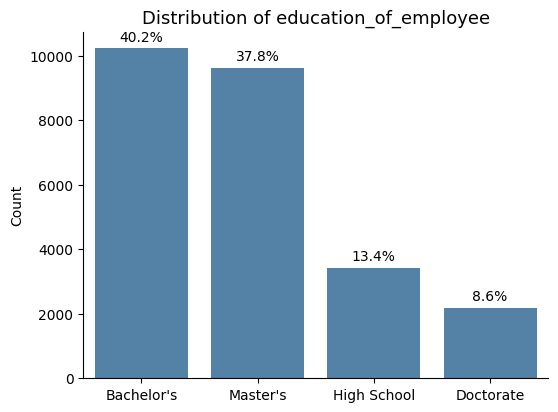

In [21]:
# Percentage of applicants by education level
labeled_barplot(data, "education_of_employee", perc=True)

##### **Observations:**
- Most applicants have a Bachelor's (40.2%) or a Master's degree (37.8%).
- 13.4% have only High School and 8.6% have a Doctorate.
- The applicants are highly educated: 86.6% have at least a Bachelor's degree.

### Observations on region of employment

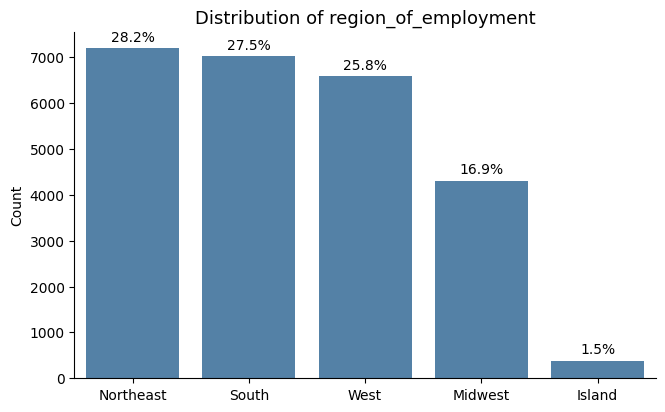

In [22]:
# Percentage of applications by region of employment in the US
labeled_barplot(data, "region_of_employment", perc=True)

##### **Observations:**
- Northeast (28.2%), South (27.5%) and West (25.9%) receive a similar share of applications.
- Midwest has 16.9% and Island only 1.5%.

### Observations on job experience

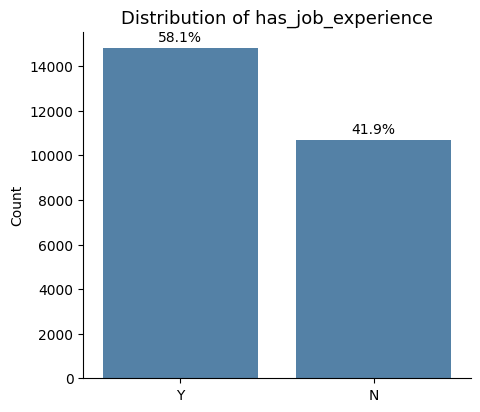

In [23]:
# Percentage of applicants with and without job experience
labeled_barplot(data, "has_job_experience", perc=True)

##### **Observations:**
- 58.1% of the applicants have job experience and 41.9% do not.

### Observations on no_of_employees

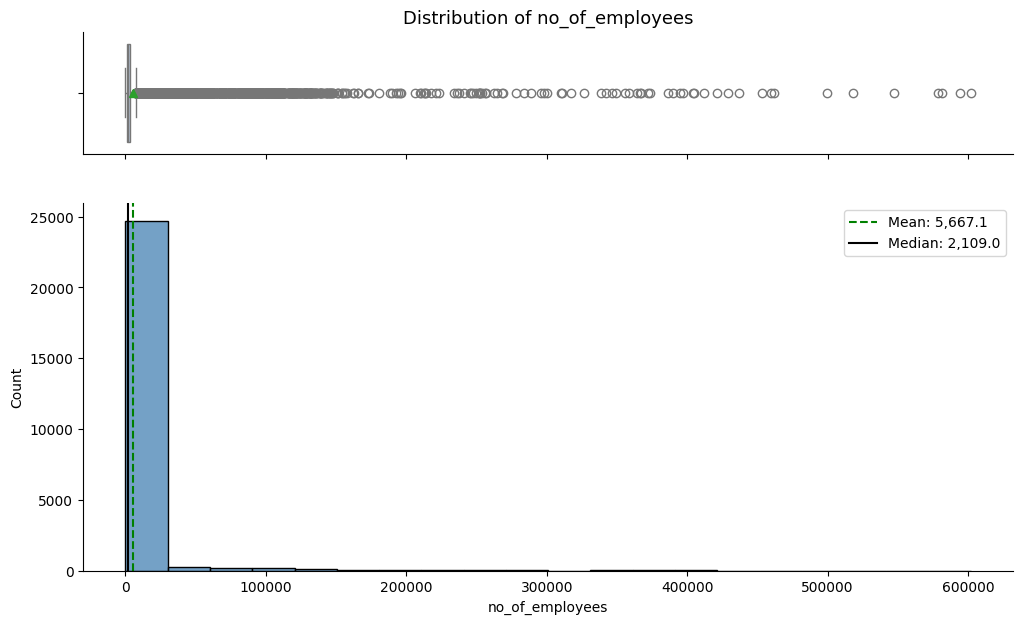

Skewness: 12.27


In [24]:
# Distribution of the number of employees of the employer's company
histogram_boxplot(data, "no_of_employees", bins=20)
print(f"Skewness: {data['no_of_employees'].skew():.2f}")

##### **Observations:**
- no_of_employees is extremely right-skewed (skewness 12.3). The median is 2,109 employees, but a few companies have up to 602,069.
- 1,556 values are outliers by the IQR rule (above ~7,200 employees). They look like real large companies, not errors.

### Observations on yr_of_estab

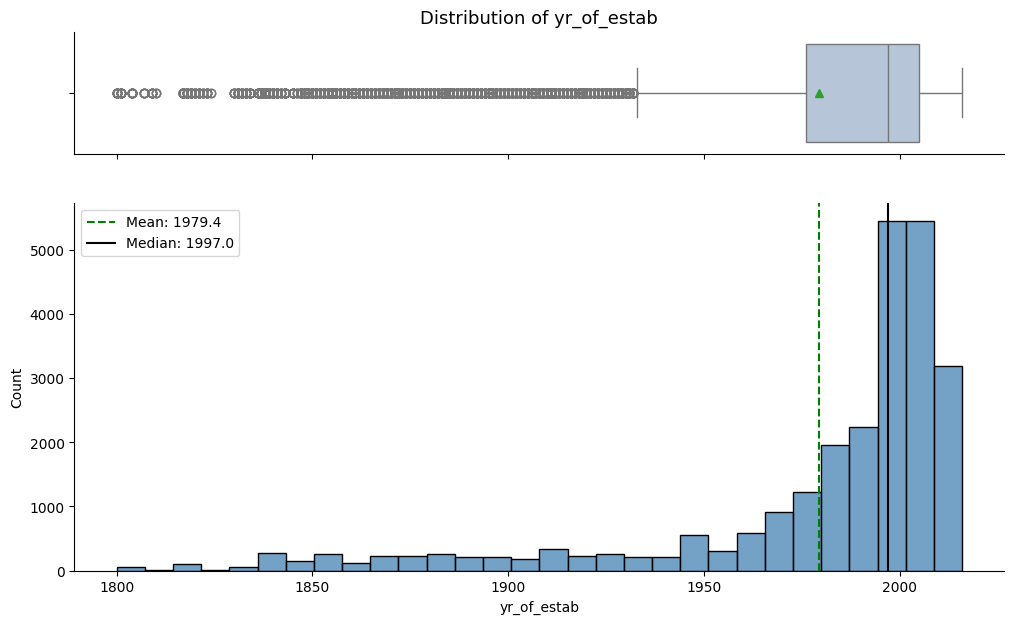

Skewness: -2.04


In [25]:
# Distribution of the year of establishment of the employer's company
histogram_boxplot(data, "yr_of_estab", bins=30, fmt=".1f")
print(f"Skewness: {data['yr_of_estab'].skew():.2f}")

##### **Observations:**
- yr_of_estab is left-skewed (skewness -2.0): most companies are recent, with a median of 1997.
- 72% of the companies were established in 1980 or later, and 41% in 2000 or later.
- The boxplot shows many outliers before ~1932. These are old companies, which is possible, so I keep them.

### Observations on full_time_position

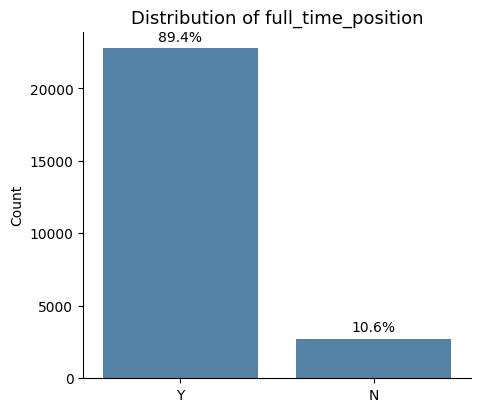

In [26]:
# Percentage of full-time and part-time positions
labeled_barplot(data, "full_time_position", perc=True)

##### **Observations:**
- 89.4% of the positions are full time and only 10.6% are part time.

### Observations on continent

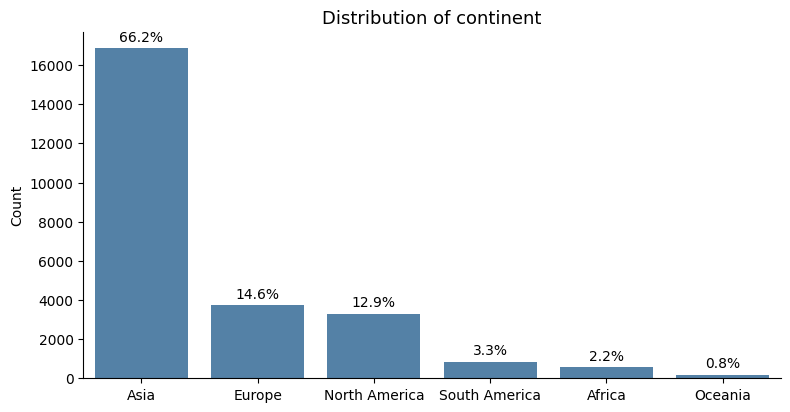

In [27]:
# Percentage of applicants by continent
labeled_barplot(data, "continent", perc=True)

##### **Observations:**
- Asia is by far the largest group (66.2%), followed by Europe (14.6%) and North America (12.9%).
- South America (3.3%), Africa (2.2%) and Oceania (0.8%) have very few applicants.

### Observations on requires_job_training

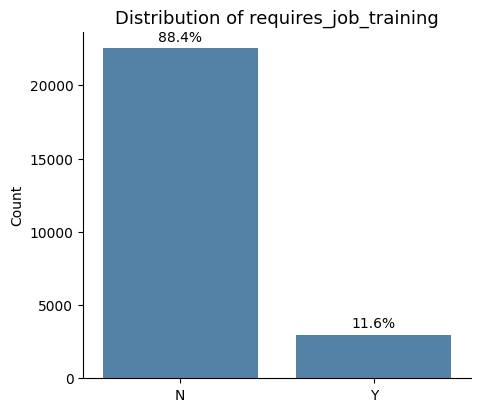

In [28]:
# Percentage of applicants who require job training
labeled_barplot(data, "requires_job_training", perc=True)

##### **Observations:**
- 88.4% of the applicants do not require job training. Only 11.6% do.

### Observations on unit_of_wage

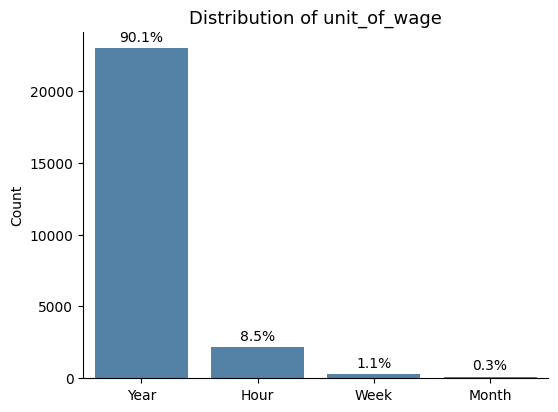

In [29]:
# Percentage of applications by unit of wage
labeled_barplot(data, "unit_of_wage", perc=True)

##### **Observations:**
- 90.1% of the wages are yearly and 8.5% hourly. Weekly (1.1%) and monthly (0.3%) wages are very rare.

### Observations on prevailing_wage

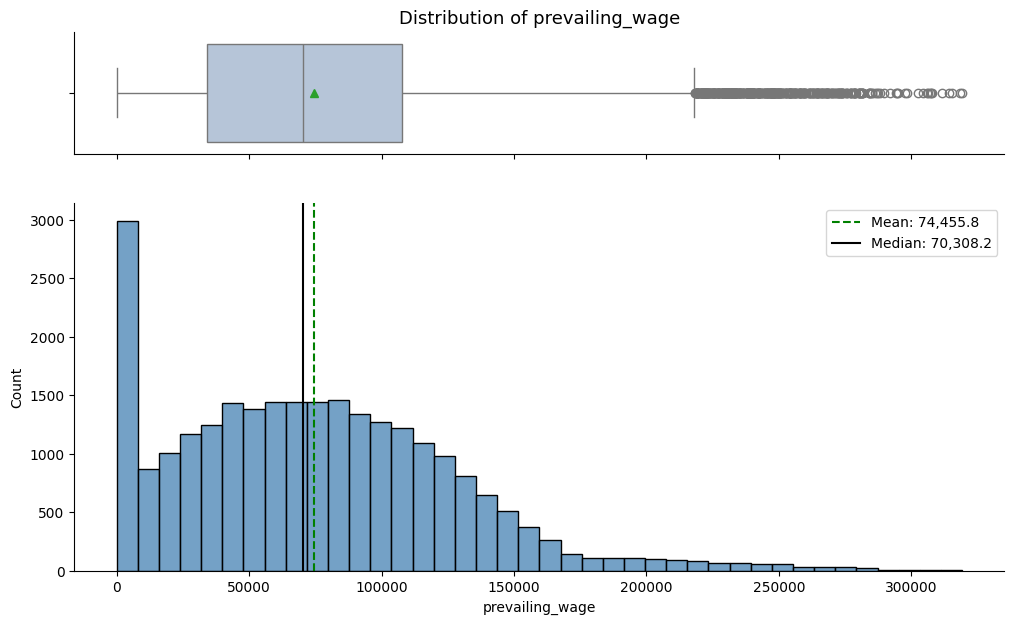

Skewness: 0.76


In [30]:
# Distribution of the prevailing wage (all units of wage together)
histogram_boxplot(data, "prevailing_wage", bins=40)
print(f"Skewness: {data['prevailing_wage'].skew():.2f}")

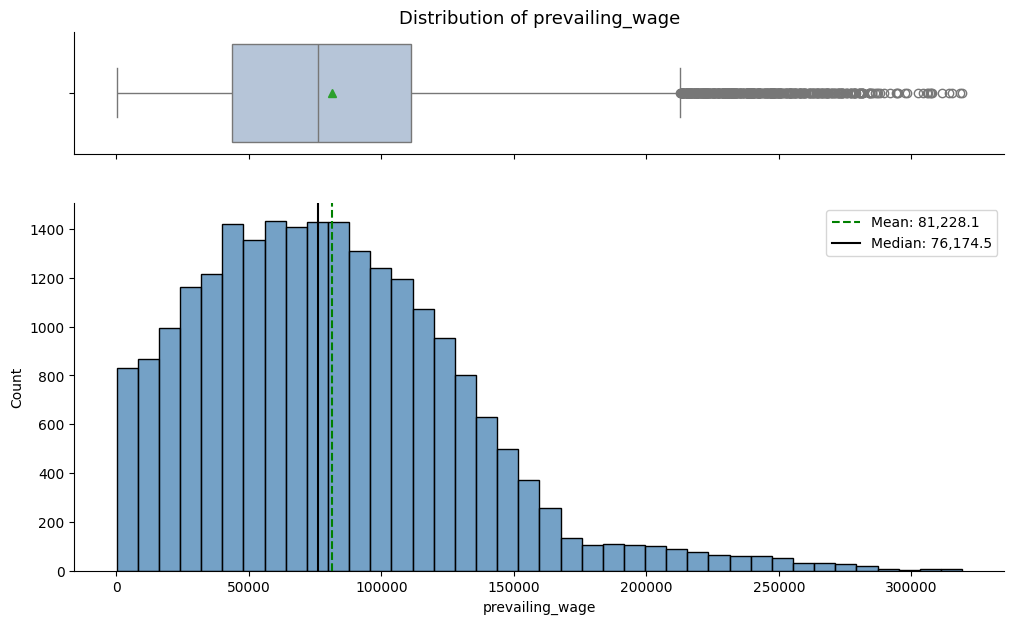

In [31]:
# Distribution of the prevailing wage only for yearly wages (90% of the data)
histogram_boxplot(data[data["unit_of_wage"] == "Year"], "prevailing_wage", bins=40)

##### **Observations:**
- prevailing_wage is right-skewed (skewness 0.76), with a median of ~70k and a maximum of ~319k.
- There is a peak of very low values near 0. These are mostly the hourly wages, so the overall distribution mixes different units.
- In the overall boxplot, 427 values are outliers by the IQR rule (above ~218k). They are possible for highly paid positions, so I keep them.
- For yearly wages only, the peak near 0 disappears and the distribution is closer to the expected salaries, with a median of ~76k.

### Prevailing wage by unit of wage

The prevailing wages for Hour, Week and Month looked too high in the sanity checks. I analyze each unit separately to check if only a few values are wrong (and could be fixed) or if the problem affects the whole unit.

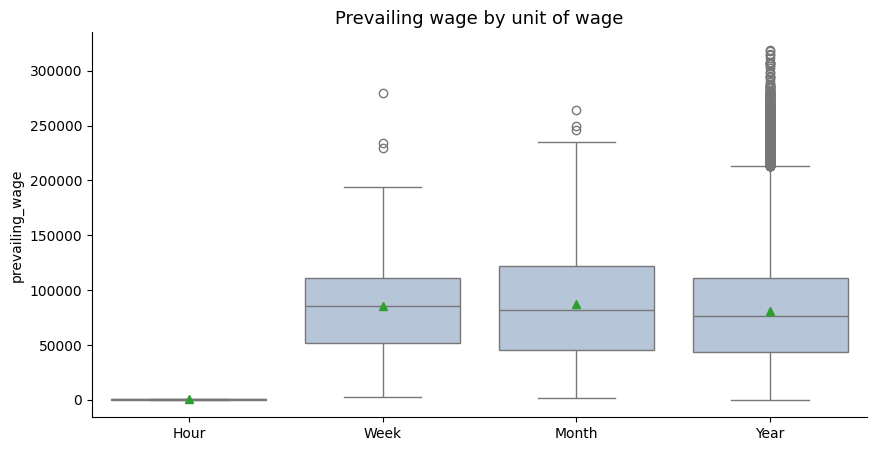

In [32]:
# Boxplot of the prevailing wage for each unit of wage
plt.figure(figsize=(10, 5))
sns.boxplot(data=data, x="unit_of_wage", y="prevailing_wage", showmeans=True, color="lightsteelblue",
            order=["Hour", "Week", "Month", "Year"])
plt.title("Prevailing wage by unit of wage", fontsize=13)
plt.xlabel("")
sns.despine()
plt.show()

#### Hourly wages

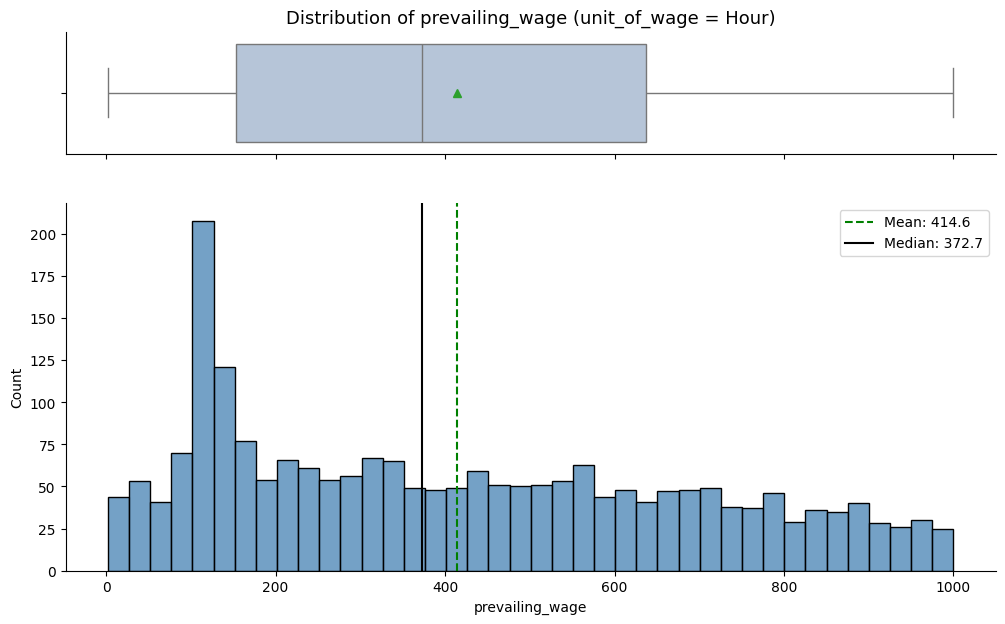

In [33]:
# Distribution of the hourly wages
hourly = data[data["unit_of_wage"] == "Hour"]
histogram_boxplot(hourly, "prevailing_wage", bins=40, title="Distribution of prevailing_wage (unit_of_wage = Hour)")

In [34]:
# Number of hourly wages in different ranges (US dollars per hour)
hour_ranges = pd.cut(hourly["prevailing_wage"], bins=[0, 15, 100, 200, 500, 1000],
                     labels=["< 15", "15 - 100", "100 - 200", "200 - 500", "500 - 1,000"])
pd.DataFrame({
    "Count": hour_ranges.value_counts().sort_index(),
    "Percentage (%)": (hour_ranges.value_counts(normalize=True).sort_index() * 100).round(1),
})

,Count,Percentage (%)
prevailing_wage,,
< 15,24,1.1
15 - 100,152,7.0
100 - 200,491,22.8
200 - 500,674,31.2
"500 - 1,000",816,37.8


#### Weekly and monthly wages

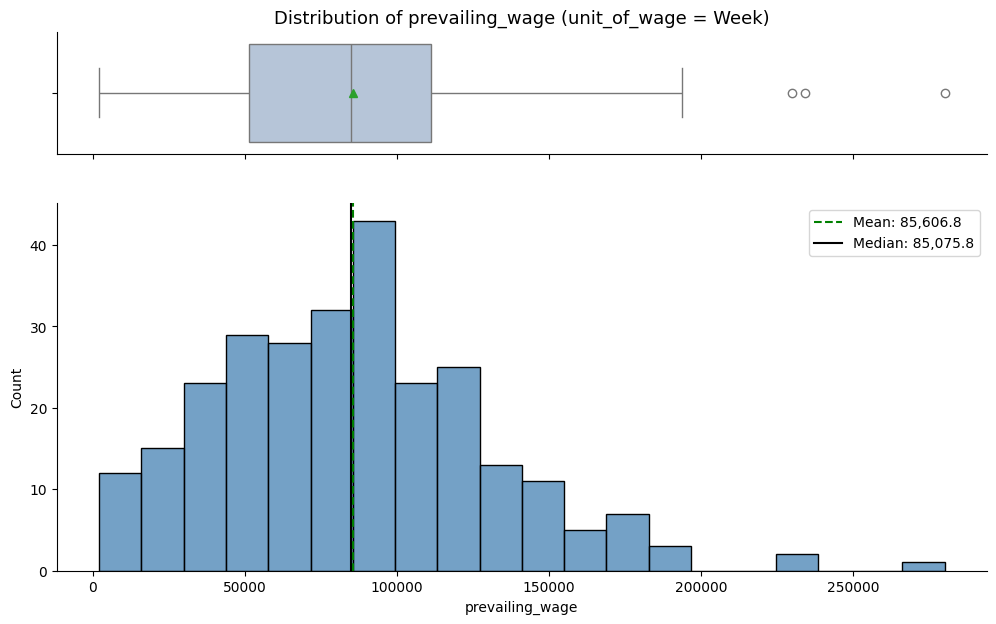

Week: median 85,076 -> annualized median 4,423,943



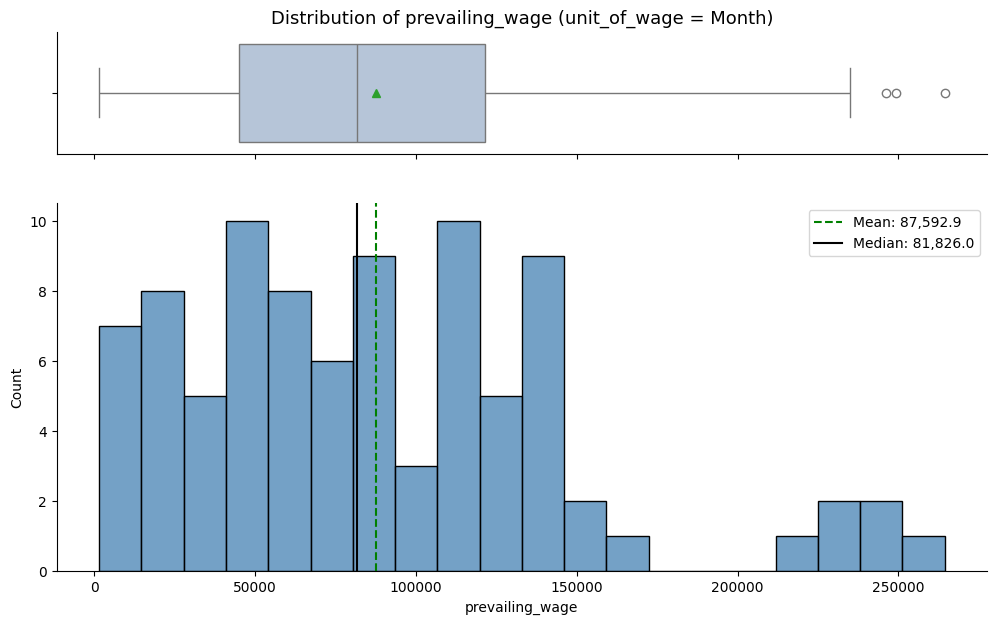

Month: median 81,826 -> annualized median 981,912



In [35]:
# Distribution of the weekly and monthly wages
for unit, periods_per_year in [("Week", 52), ("Month", 12)]:
    subset = data[data["unit_of_wage"] == unit]
    histogram_boxplot(subset, "prevailing_wage", bins=20,
                      title=f"Distribution of prevailing_wage (unit_of_wage = {unit})")

    # If the values were really weekly/monthly, the annual wage would be the median x periods per year
    median = subset["prevailing_wage"].median()
    print(f"{unit}: median {median:,.0f} -> annualized median {median * periods_per_year:,.0f}\n")

#### Very low yearly wages

In [36]:
# Yearly wages that are too low for an annual salary
yearly = data[data["unit_of_wage"] == "Year"]
print(f"Yearly wages below 10,000: {(yearly['prevailing_wage'] < 10_000).sum()}")
print(f"Yearly wages below 1,000:  {(yearly['prevailing_wage'] < 1_000).sum()}")
print(f"Minimum yearly wage:       {yearly['prevailing_wage'].min():,.2f}")

Yearly wages below 10,000: 1038
Yearly wages below 1,000:  110
Minimum yearly wage:       100.00


##### **Observations:**
- The problem is not limited to a few values. It affects the whole distribution of each unit:
  - Hour: only 8% of the hourly wages are below 100 USD per hour. 92% are between 100 and 1,000 USD per hour, spread across the whole range with a peak between 100 and 200, which is not realistic for hourly wages.
  - Week and Month: their distributions are very similar to the yearly wages (medians of ~85k and ~82k). If these values were really weekly or monthly, the annual wages would be ~4.4 million and ~1 million USD.
- Yearly wages also have unrealistic values: 1,038 are below 10,000 USD per year and 110 are below 1,000.
- Since there is no clear rule to identify and fix the wrong values, I do not adjust them. I keep prevailing_wage as it is and keep unit_of_wage as a feature, so the models can treat the wages differently depending on the unit.

### What is the distribution of visa case statuses (certified vs. denied)?

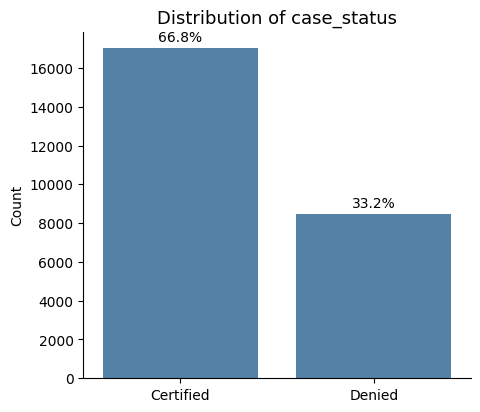

In [37]:
# Percentage of certified and denied visa applications (target variable)
labeled_barplot(data, "case_status", perc=True)

##### **Observations:**
- 66.8% of the visa applications were certified and 33.2% were denied.
- The target is imbalanced (about 2 certified for every denied application). I will use stratify in the train-test split and keep this in mind when choosing the evaluation metric.

## Bivariate Analysis

### Correlation between the numerical variables

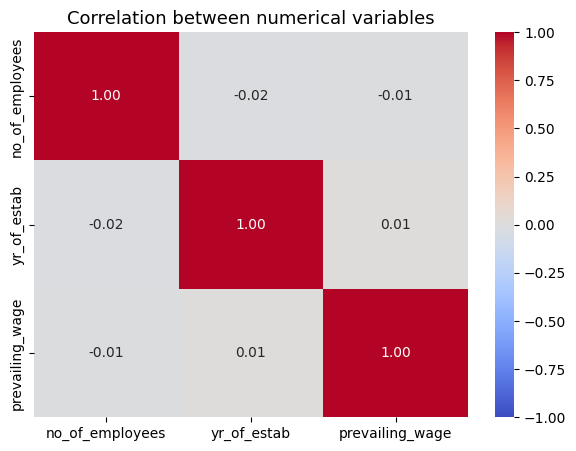

In [38]:
# Correlation heatmap of the numerical variables
cols_list = data.select_dtypes(include=np.number).columns.tolist()

plt.figure(figsize=(7, 5))
sns.heatmap(data[cols_list].corr(), annot=True, vmin=-1, vmax=1, fmt=".2f", cmap="coolwarm")
plt.title("Correlation between numerical variables", fontsize=13)
plt.show()

##### **Observations:**
- The three numerical variables are almost not correlated with each other (all correlations are between -0.02 and 0.01).
- There is no multicollinearity problem between them.

### Functions required for the bivariate analysis

In [39]:
# Colors used for the target classes in all the bivariate plots
CERTIFIED_COLOR = "forestgreen" 
DENIED_COLOR = "firebrick"

In [40]:
# function to plot the certification rate of each category of a predictor


def stacked_barplot(data, predictor, target="case_status"):
    """
    Print the category counts and plot a 100% stacked bar chart

    data: dataframe
    predictor: independent variable
    target: target variable (default "case_status")
    """
    # Counts of each category by target (sorted by certification rate)
    tab = pd.crosstab(data[predictor], data[target], normalize="index")[["Certified", "Denied"]]
    tab = tab.sort_values(by="Certified", ascending=False)
    counts = pd.crosstab(data[predictor], data[target], margins=True, margins_name="Total")
    counts = counts.loc[list(tab.index) + ["Total"], ["Certified", "Denied", "Total"]]
    counts["Certified (%)"] = (counts["Certified"] / counts["Total"] * 100).round(1)
    print(counts)
    print("-" * 70)

    # 100% stacked bar chart
    count = data[predictor].nunique()
    ax = (tab * 100).plot(
        kind="bar", stacked=True, figsize=(max(1.5 * count, 5), 4.5),
        color=[CERTIFIED_COLOR, DENIED_COLOR], width=0.7,
    )

    # Percentage inside each segment
    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f%%", label_type="center", fontsize=10, color="white")

    # Overall certification rate as reference
    overall = (data[target] == "Certified").mean() * 100
    ax.axhline(overall, color="black", linestyle="--", linewidth=1, label=f"Overall certified: {overall:.1f}%")

    ax.set_title(f"case_status by {predictor}", fontsize=13)
    ax.set_xlabel("")
    ax.set_ylabel("Percentage (%)")
    plt.xticks(rotation=0, fontsize=10)
    plt.yticks(fontsize=10)
    ax.legend(loc="upper left", bbox_to_anchor=(1, 1), fontsize=10, frameon=False)
    sns.despine()
    plt.show()

In [41]:
# function to plot the distribution of a numerical predictor for each target class


def distribution_plot_wrt_target(data, predictor, target="case_status"):
    """
    Histograms of the predictor for each target class, and boxplots with and without outliers

    data: dataframe
    predictor: numerical independent variable
    target: target variable (default "case_status")
    """
    classes = ["Certified", "Denied"]
    colors = {"Certified": CERTIFIED_COLOR, "Denied": DENIED_COLOR}

    fig, axs = plt.subplots(2, 2, figsize=(12, 9))

    # Histograms for each target class
    for ax, cls in zip(axs[0], classes):
        sns.histplot(data=data[data[target] == cls], x=predictor, kde=True, ax=ax,
                     color=colors[cls], stat="density")
        ax.set_title(f"Distribution of {predictor} for {target} = {cls}", fontsize=11)

    # Boxplots with and without outliers
    sns.boxplot(data=data, x=target, y=predictor, order=classes, palette=colors,
                showmeans=True, ax=axs[1, 0])
    axs[1, 0].set_title(f"{predictor} by {target}", fontsize=11)
    sns.boxplot(data=data, x=target, y=predictor, order=classes, palette=colors,
                showmeans=True, showfliers=False, ax=axs[1, 1])
    axs[1, 1].set_title(f"{predictor} by {target} (without outliers)", fontsize=11)

    for ax in axs.flatten():
        ax.tick_params(labelsize=10)
    sns.despine()
    plt.tight_layout()
    plt.show()

    # Mean and median of the predictor for each target class
    print(data.groupby(target)[predictor].agg(["mean", "median"]).round(1))

In [42]:
# function to show the certification rate by quartiles of a numerical predictor


def certification_rate_by_quartile(data, predictor, target="case_status"):
    """
    Certification rate (%) for each quartile of a numerical predictor

    data: dataframe
    predictor: numerical independent variable
    target: target variable (default "case_status")
    """
    quartiles = pd.qcut(data[predictor], q=4)
    summary = data.groupby(quartiles, observed=True)[target].agg(
        Applications="size",
        Certified_pct=lambda x: round((x == "Certified").mean() * 100, 1),
    )
    summary.index.name = f"{predictor} (quartile)"
    return summary.rename(columns={"Certified_pct": "Certified (%)"})

### How does the education level of employees impact visa approval rates?

case_status            Certified  Denied  Total  Certified (%)
education_of_employee                                         
Doctorate                   1912     280   2192           87.2
Master's                    7575    2059   9634           78.6
Bachelor's                  6367    3867  10234           62.2
High School                 1164    2256   3420           34.0
Total                      17018    8462  25480           66.8
----------------------------------------------------------------------


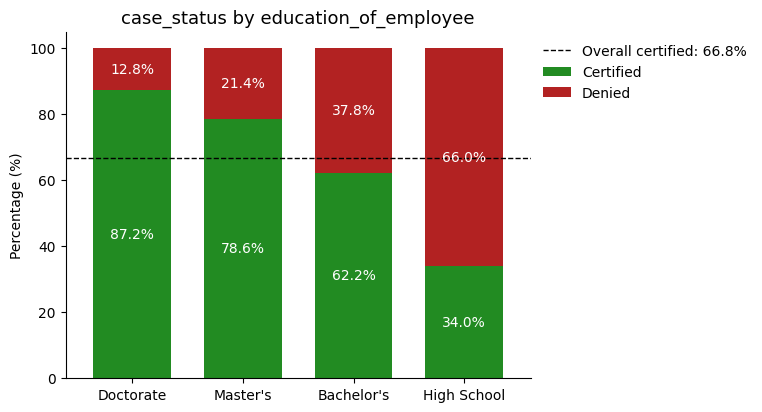

In [43]:
# Certification rate by education level
stacked_barplot(data, "education_of_employee")

##### **Observations:**
- Education has a strong impact on visa approval: the higher the education level, the higher the certification rate.
- Doctorate: 87.2%, Master's: 78.6%, Bachelor's: 62.2% and High School: only 34.0%.
- High School is the only level where most applications are denied.

### Are visa approval rates different across various continents of employees? Which continent has the highest and lowest approval rates?

case_status    Certified  Denied  Total  Certified (%)
continent                                             
Europe              2957     775   3732           79.2
Africa               397     154    551           72.1
Asia               11012    5849  16861           65.3
Oceania              122      70    192           63.5
North America       2037    1255   3292           61.9
South America        493     359    852           57.9
Total              17018    8462  25480           66.8
----------------------------------------------------------------------


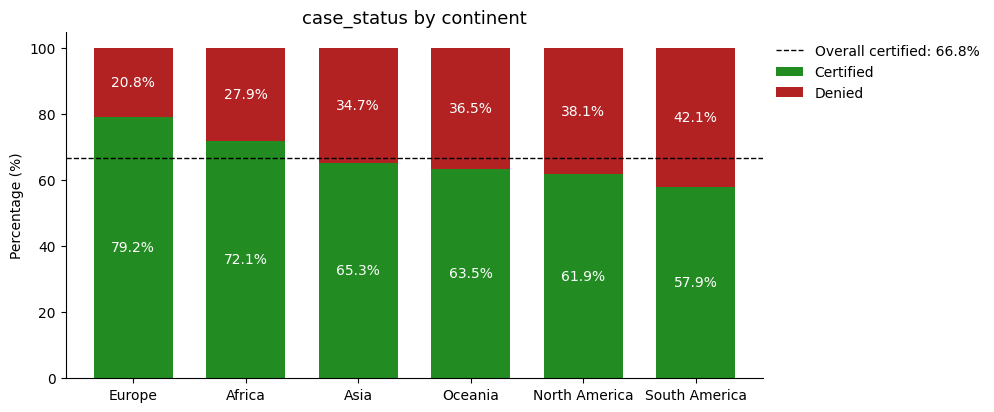

In [44]:
# Certification rate by continent
stacked_barplot(data, "continent")

##### **Observations:**
- Yes, approval rates differ across continents.
- Europe has the highest certification rate (79.2%), followed by Africa (72.1%).
- South America has the lowest (57.9%), followed by North America (61.9%).
- Asia, the largest group, is close to the overall rate (65.3%).

### Is there a significant difference in visa approval rates between employees with and without prior job experience?

case_status         Certified  Denied  Total  Certified (%)
has_job_experience                                         
Y                       11024    3778  14802           74.5
N                        5994    4684  10678           56.1
Total                   17018    8462  25480           66.8
----------------------------------------------------------------------


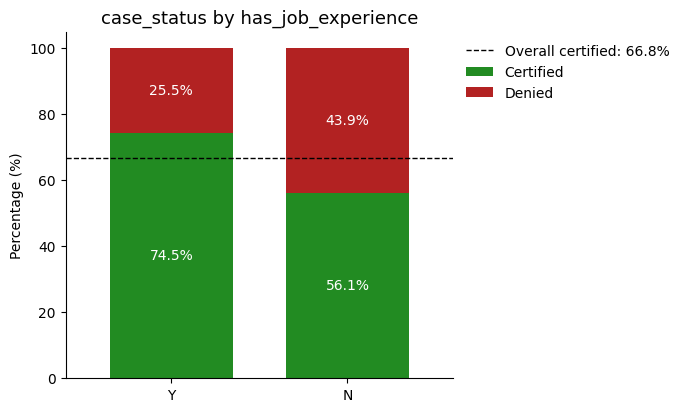

In [45]:
# Certification rate by job experience
stacked_barplot(data, "has_job_experience")

##### **Observations:**
- Yes. Applicants with job experience have a certification rate of 74.5%, compared to 56.1% for applicants without experience (a difference of ~18 percentage points).

### Observations on requires_job_training and case_status

case_status            Certified  Denied  Total  Certified (%)
requires_job_training                                         
Y                           2006     949   2955           67.9
N                          15012    7513  22525           66.6
Total                      17018    8462  25480           66.8
----------------------------------------------------------------------


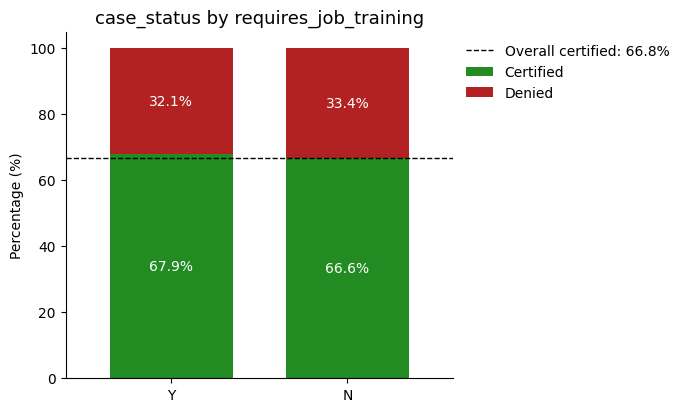

In [46]:
# Certification rate by job training requirement
stacked_barplot(data, "requires_job_training")

##### **Observations:**
- Requiring job training has almost no impact on approval: 67.9% (Y) vs. 66.6% (N).

### Do certain regions in the US have higher visa approval rates compared to others?

case_status           Certified  Denied  Total  Certified (%)
region_of_employment                                         
Midwest                    3253    1054   4307           75.5
South                      4913    2104   7017           70.0
Northeast                  4526    2669   7195           62.9
West                       4100    2486   6586           62.3
Island                      226     149    375           60.3
Total                     17018    8462  25480           66.8
----------------------------------------------------------------------


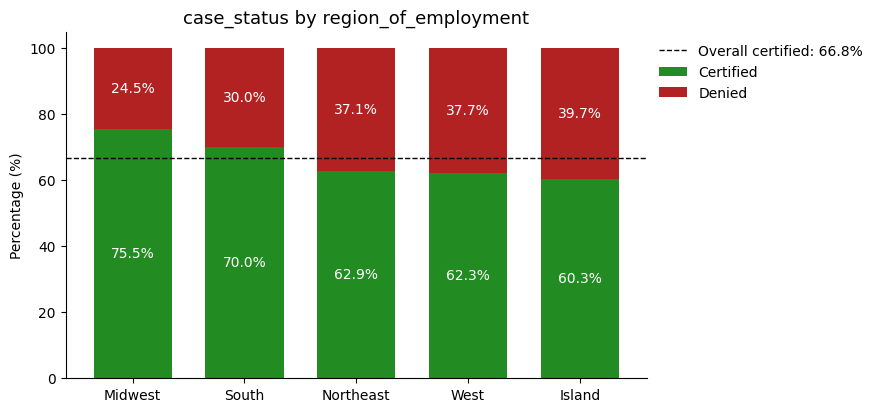

In [47]:
# Certification rate by region of employment
stacked_barplot(data, "region_of_employment")

##### **Observations:**
- Yes. Midwest has the highest certification rate (75.5%), followed by South (70.0%).
- Northeast (62.9%), West (62.3%) and Island (60.3%) are below the overall rate.

### Observations on prevailing_wage and region_of_employment

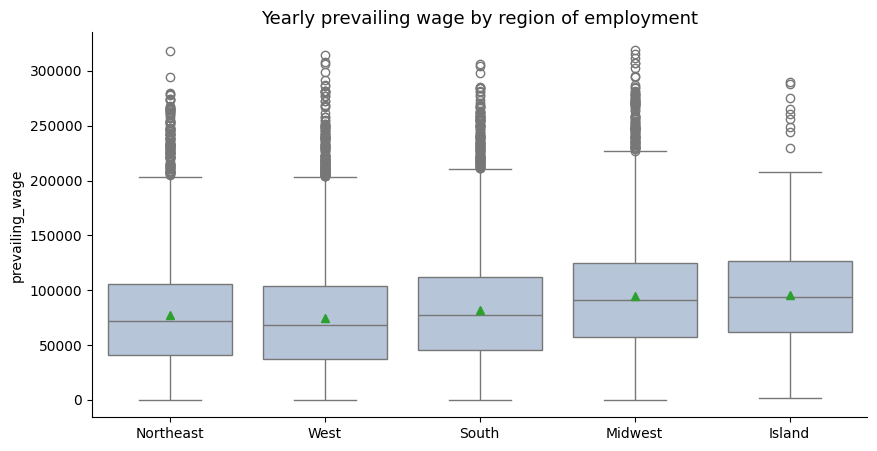

region_of_employment
Island       93528.0
Midwest      91357.0
South        76946.0
Northeast    72130.0
West         68485.0
Name: prevailing_wage, dtype: float64

In [48]:
# Prevailing wage by region (only yearly wages, to compare values in the same unit)
plt.figure(figsize=(10, 5))
sns.boxplot(data=data[data["unit_of_wage"] == "Year"], x="region_of_employment", y="prevailing_wage",
            showmeans=True, color="lightsteelblue")
plt.title("Yearly prevailing wage by region of employment", fontsize=13)
plt.xlabel("")
sns.despine()
plt.show()

# Median yearly wage by region
data[data["unit_of_wage"] == "Year"].groupby("region_of_employment")["prevailing_wage"].median().round(0).sort_values(ascending=False)

##### **Observations:**
- I only use yearly wages here, so that all the values are in the same unit.
- Island (~94k) and Midwest (~91k) have the highest median yearly wages. West (~68k) and Northeast (~72k) have the lowest.
- Midwest combines a high wage with the highest certification rate.

### How does the prevailing wage affect visa approval? Do higher wages lead to higher chances of approval?

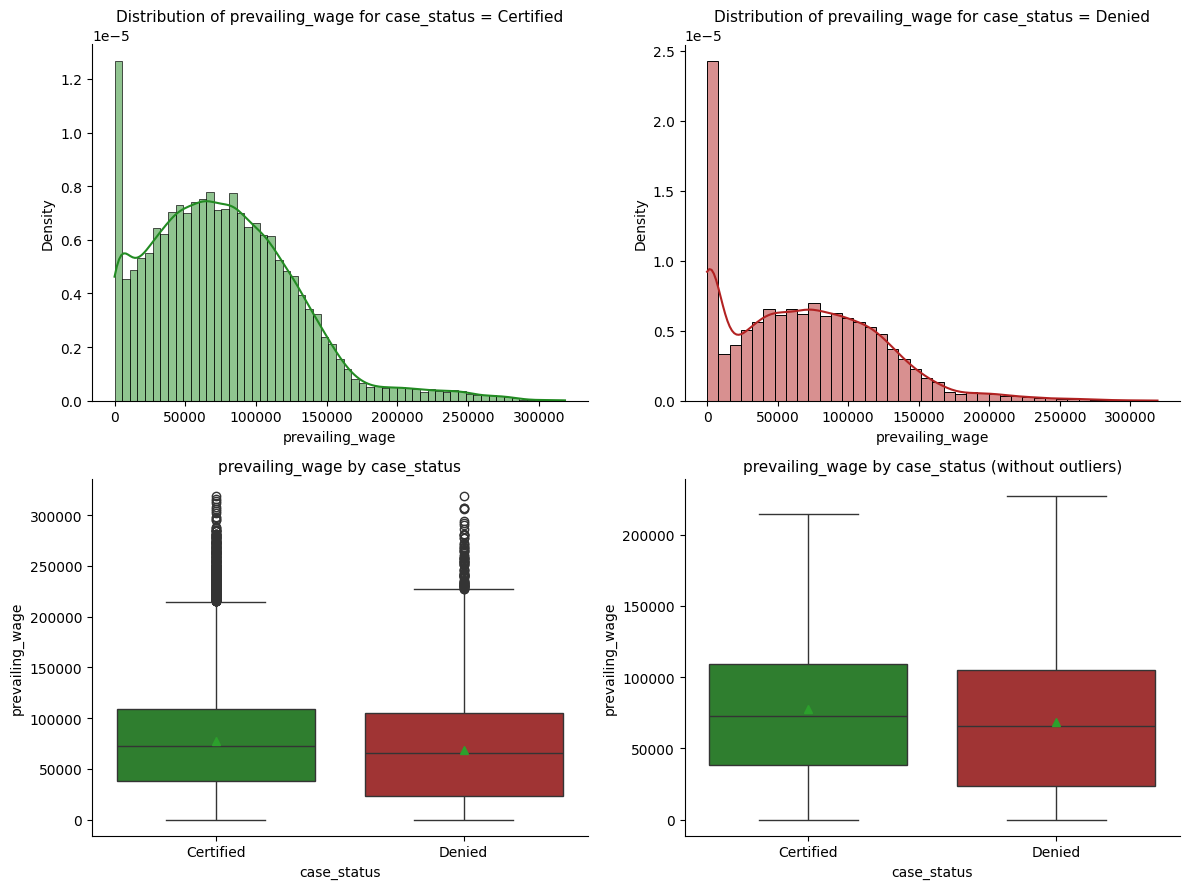

                mean   median
case_status                  
Certified    77293.6  72486.3
Denied       68748.7  65431.5


In [49]:
# Distribution of the prevailing wage by case status (all units of wage)
distribution_plot_wrt_target(data, "prevailing_wage")

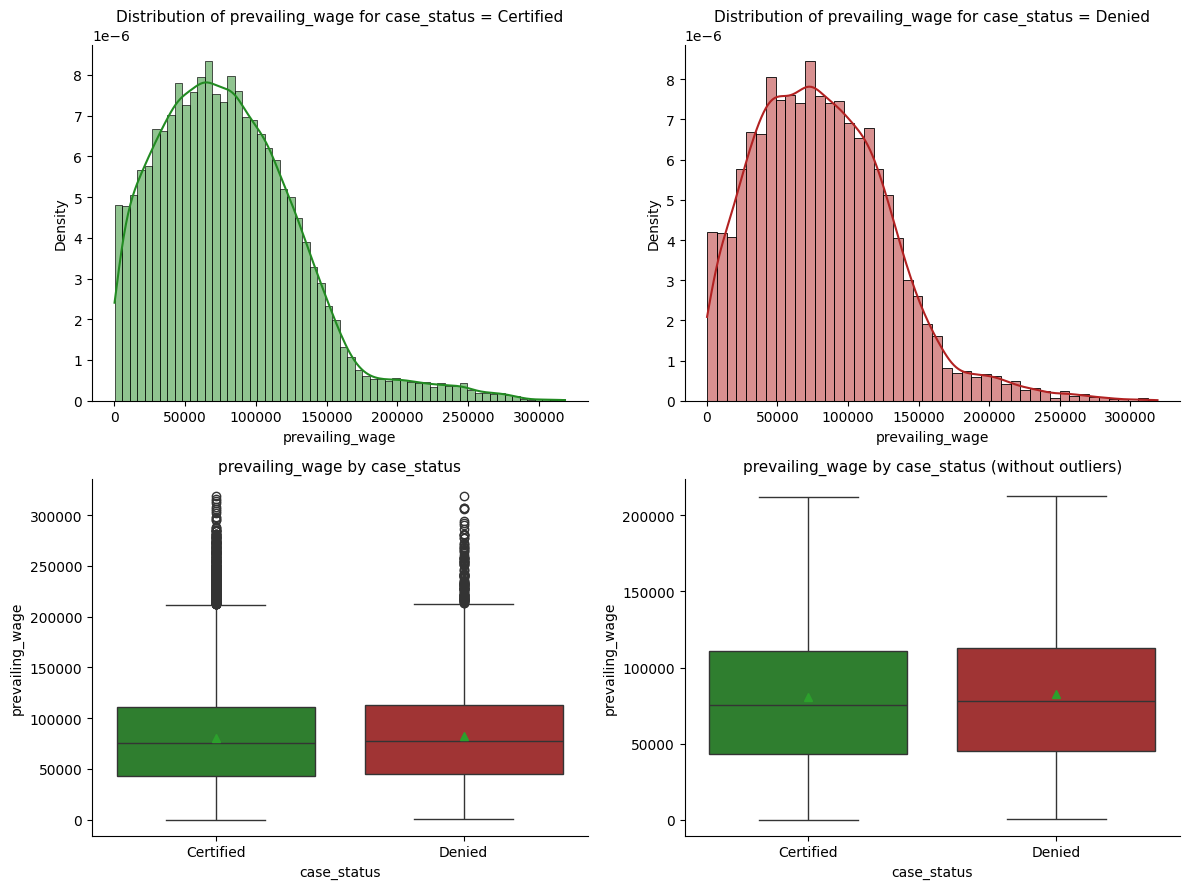

                mean   median
case_status                  
Certified    80746.4  75427.8
Denied       82345.8  77697.2


In [50]:
# Same analysis only for yearly wages (90% of the data), to compare values in the same unit
yearly = data[data["unit_of_wage"] == "Year"]
distribution_plot_wrt_target(yearly, "prevailing_wage")

In [51]:
# Certification rate by quartiles of the yearly wage
certification_rate_by_quartile(yearly, "prevailing_wage")

,Applications,Certified (%)
prevailing_wage (quartile),,
"(99.999, 43715.955]",5741,71.6
"(43715.955, 76174.5]",5740,69.8
"(76174.5, 111341.96]",5740,69.5
"(111341.96, 319210.27]",5741,68.7


##### **Observations:**
- With all units together, certified applications have a higher median wage (~72k) than denied ones (~65k). However, this difference comes from the hourly wages, which have low numerical values and a low certification rate (see unit_of_wage below).
- When I only look at yearly wages, the distributions for certified and denied applications are almost the same (medians ~75k and ~78k).
- The certification rate is very similar in all the quartiles of the yearly wage (between 68.7% and 71.6%).
- So higher wages do not lead to higher chances of approval. The unit of wage matters more than the amount.

### Observations on unit_of_wage and case_status

case_status   Certified  Denied  Total  Certified (%)
unit_of_wage                                         
Year              16047    6915  22962           69.9
Week                169     103    272           62.1
Month                55      34     89           61.8
Hour                747    1410   2157           34.6
Total             17018    8462  25480           66.8
----------------------------------------------------------------------


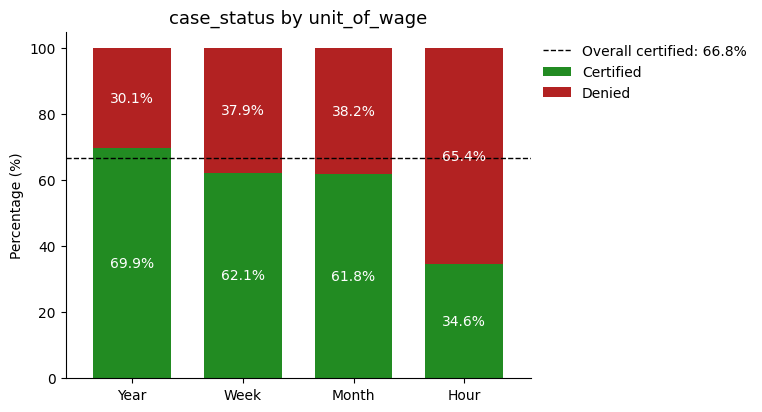

In [52]:
# Certification rate by unit of wage
stacked_barplot(data, "unit_of_wage")

##### **Observations:**
- Hourly wages have a very low certification rate (34.6%). It is the only unit where most applications are denied.
- Yearly wages have the highest rate (69.9%). Weekly (62.1%) and monthly (61.8%) are in between.
- unit_of_wage is an important driver of visa approval.

### How does the number of employees in a company influence visa approval? Do larger companies have a higher approval rate?

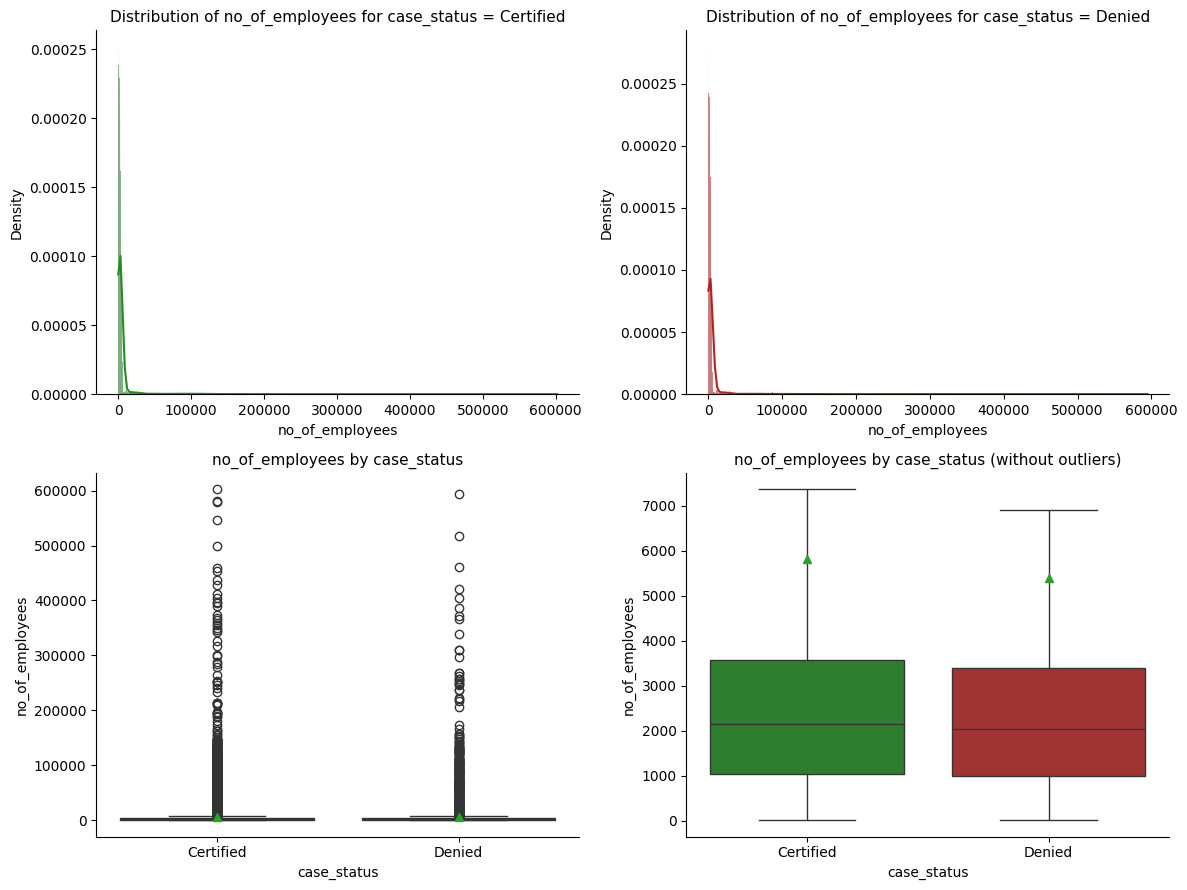

               mean  median
case_status                
Certified    5807.1  2147.0
Denied       5385.6  2032.5


In [53]:
# Distribution of the number of employees by case status
distribution_plot_wrt_target(data, "no_of_employees")

In [54]:
# Certification rate by quartiles of the number of employees
certification_rate_by_quartile(data, "no_of_employees")

,Applications,Certified (%)
no_of_employees (quartile),,
"(10.999, 1022.0]",6376,65.9
"(1022.0, 2109.0]",6368,65.6
"(2109.0, 3504.0]",6369,66.0
"(3504.0, 602069.0]",6367,69.6


##### **Observations:**
- The distributions of no_of_employees for certified and denied applications are very similar (medians of ~2,150 and ~2,030 employees).
- Only the largest companies (top quartile, more than ~3,500 employees) have a slightly higher certification rate (69.6% vs. ~66% for the other quartiles).
- Company size has a weak influence on visa approval.

### Observations on yr_of_estab and case_status

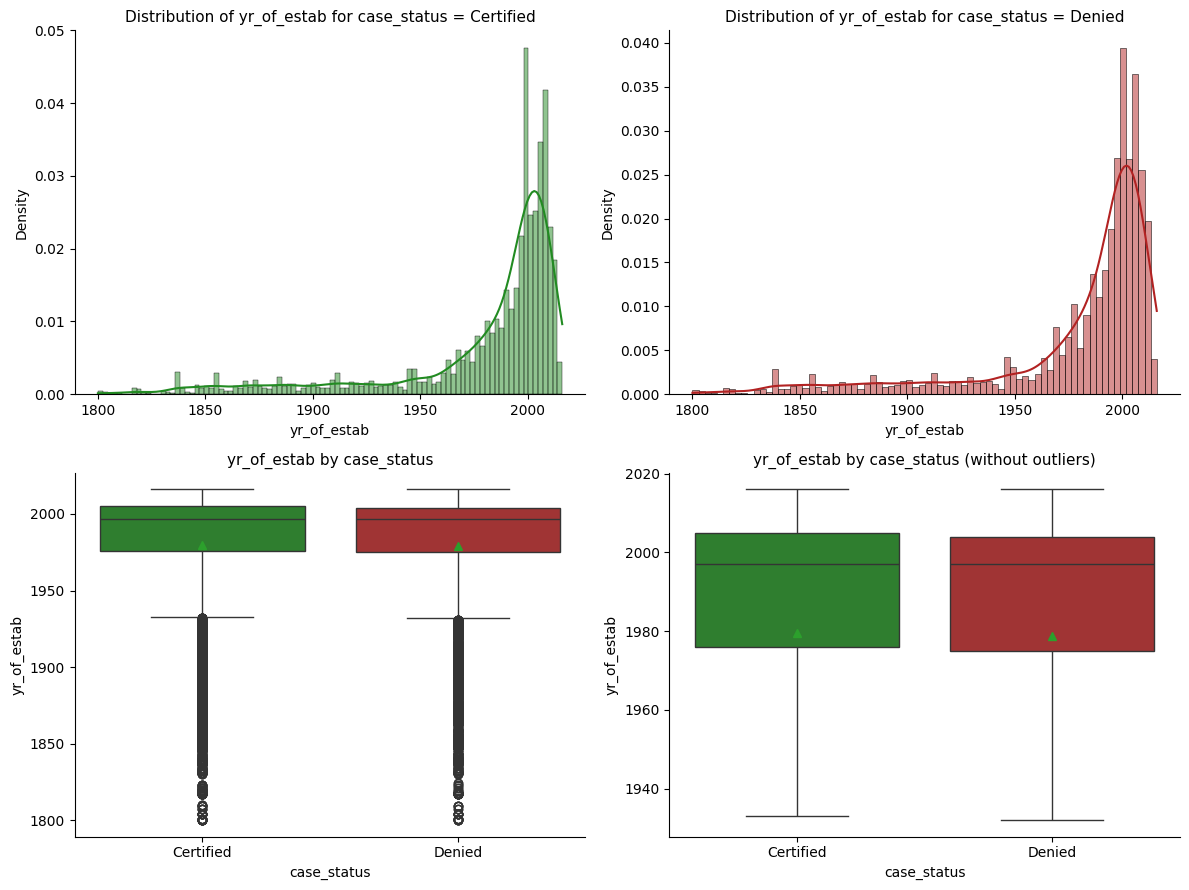

               mean  median
case_status                
Certified    1979.7  1997.0
Denied       1978.9  1997.0


In [55]:
# Distribution of the year of establishment by case status
distribution_plot_wrt_target(data, "yr_of_estab")

In [56]:
# Certification rate by quartiles of the year of establishment
certification_rate_by_quartile(data, "yr_of_estab")

,Applications,Certified (%)
yr_of_estab (quartile),,
"(1799.999, 1976.0]",6472,66.3
"(1976.0, 1997.0]",6535,65.9
"(1997.0, 2005.0]",6773,65.7
"(2005.0, 2016.0]",5700,69.6


##### **Observations:**
- The year of establishment has almost no relation with the case status: both classes have a median of 1997.
- Only the most recent companies (established after 2005) have a slightly higher certification rate (69.6% vs. ~66%).

### Observations on full_time_position and case_status

case_status         Certified  Denied  Total  Certified (%)
full_time_position                                         
N                        1855     852   2707           68.5
Y                       15163    7610  22773           66.6
Total                   17018    8462  25480           66.8
----------------------------------------------------------------------


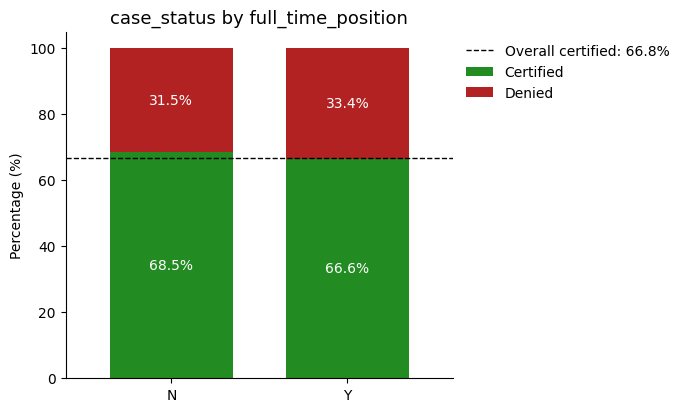

In [57]:
# Certification rate by full-time position
stacked_barplot(data, "full_time_position")

##### **Observations:**
- Full-time position has almost no impact on approval: 66.6% (Y) vs. 68.5% (N).

## Multivariate Analysis

The bivariate analysis showed that education, job experience and continent are strong drivers of visa approval. Here I check how they interact, using the certification rate of each combination.

In [58]:
# function to plot a heatmap of the certification rate for two categorical variables


def certification_rate_heatmap(data, row, col, row_order=None, col_order=None, target="case_status"):
    """
    Heatmap of the certification rate (%) for each combination of two categorical variables,
    with the number of applications of each combination in brackets

    data: dataframe
    row: categorical variable for the rows
    col: categorical variable for the columns
    row_order / col_order: order of the categories (default None, i.e., sorted by certification rate)
    target: target variable (default "case_status")
    """
    certified = data[target] == "Certified"
    rate = certified.groupby([data[row], data[col]]).mean().unstack() * 100
    counts = certified.groupby([data[row], data[col]]).size().unstack()

    # Order of the categories (by default, from highest to lowest certification rate)
    row_order = row_order or certified.groupby(data[row]).mean().sort_values(ascending=False).index.tolist()
    col_order = col_order or certified.groupby(data[col]).mean().sort_values(ascending=False).index.tolist()
    rate = rate.loc[row_order, col_order]
    counts = counts.loc[row_order, col_order]

    # Cell labels: certification rate and number of applications
    labels = rate.round(1).astype(str) + "%\n(" + counts.astype(int).astype(str) + ")"

    # Red-green colormap centered on the overall certification rate
    overall = certified.mean() * 100
    plt.figure(figsize=(1.6 * len(col_order) + 2, 0.9 * len(row_order) + 2))
    sns.heatmap(rate, annot=labels, fmt="", cmap="RdYlGn", center=overall, vmin=20, vmax=100,
                annot_kws={"size": 10}, cbar_kws={"label": "Certified (%)"}, linewidths=0.5)
    plt.title(f"Certification rate by {row} and {col}\n(overall: {overall:.1f}%, number of applications in brackets)",
              fontsize=12)
    plt.xlabel(col, fontsize=10)
    plt.ylabel(row, fontsize=10)
    plt.xticks(fontsize=10, rotation=0)
    plt.yticks(fontsize=10, rotation=0)
    plt.show()

In [59]:
# Order of the education levels, from lowest to highest
education_order = ["High School", "Bachelor's", "Master's", "Doctorate"]

### Education level and job experience

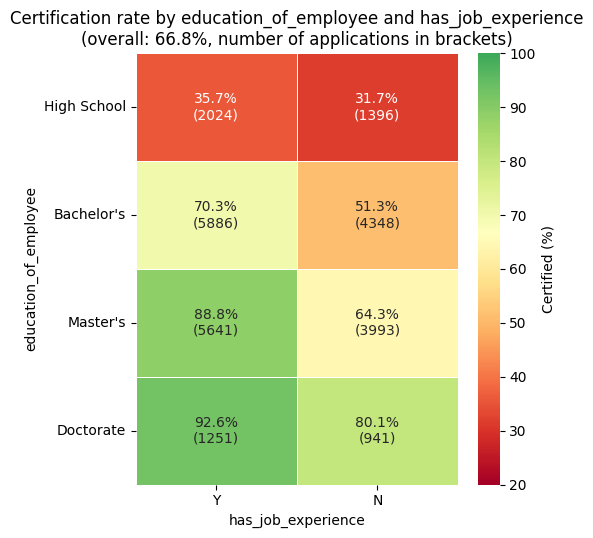

In [60]:
# Certification rate by education level and job experience
certification_rate_heatmap(data, row="education_of_employee", col="has_job_experience",
                           row_order=education_order, col_order=["Y", "N"])

##### **Observations:**
- Job experience increases the certification rate at every education level.
- The effect is largest for Master's (88.8% with experience vs. 64.3% without) and Bachelor's (70.3% vs. 51.3%).
- A Master's degree with experience (88.8%) has a higher rate than a Doctorate without experience (80.1%).
- High School applicants have a low rate with or without experience (35.7% vs. 31.7%).
- The best profile is a Doctorate with job experience (92.6%), and the worst is High School without experience (31.7%).

### Continent and education level

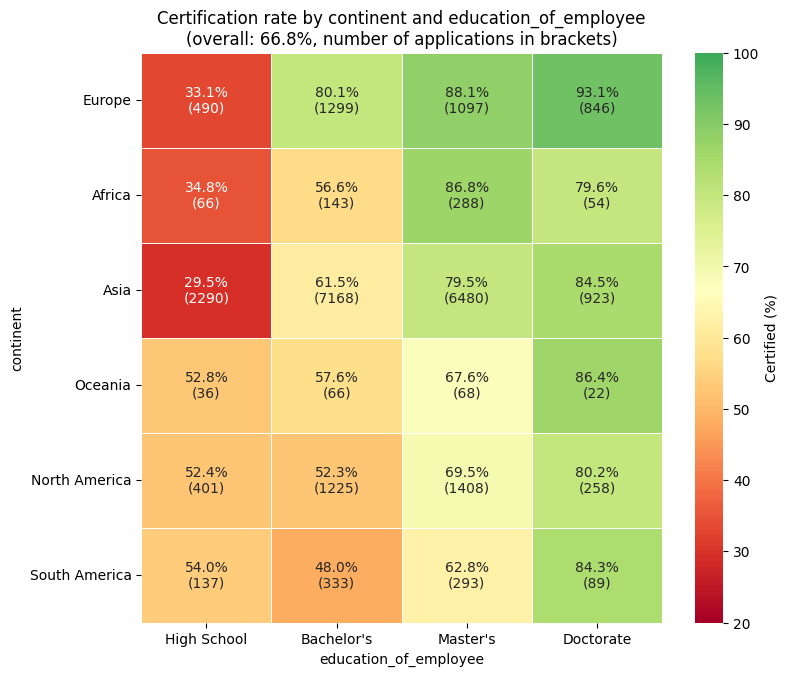

In [61]:
# Certification rate by continent and education level
certification_rate_heatmap(data, row="continent", col="education_of_employee", col_order=education_order)

##### **Observations:**
- A higher education level increases the certification rate in every continent. Doctorates have rates above 79% everywhere.
- High School applicants from Europe, Africa and Asia have very low rates (~30–35%), while those from North America, South America and Oceania have higher rates (~52–54%).
- Europe has the highest rates for Bachelor's (80.1%), Master's (88.1%) and Doctorate (93.1%).
- Asia has the largest High School group (2,290 applications) with the lowest rate (29.5%), which pulls down its overall rate.
- Some combinations have few applications (e.g. Oceania, Africa), so their rates are less reliable.

# **Data Pre-processing**

In [62]:
# Missing values per column (already checked in the overview, confirmed here before modeling)
print(f"Total missing values: {data.isnull().sum().sum()}")

Total missing values: 0


##### **Observations:**
- There are no missing values, so no missing value treatment is needed.

## Outlier Check

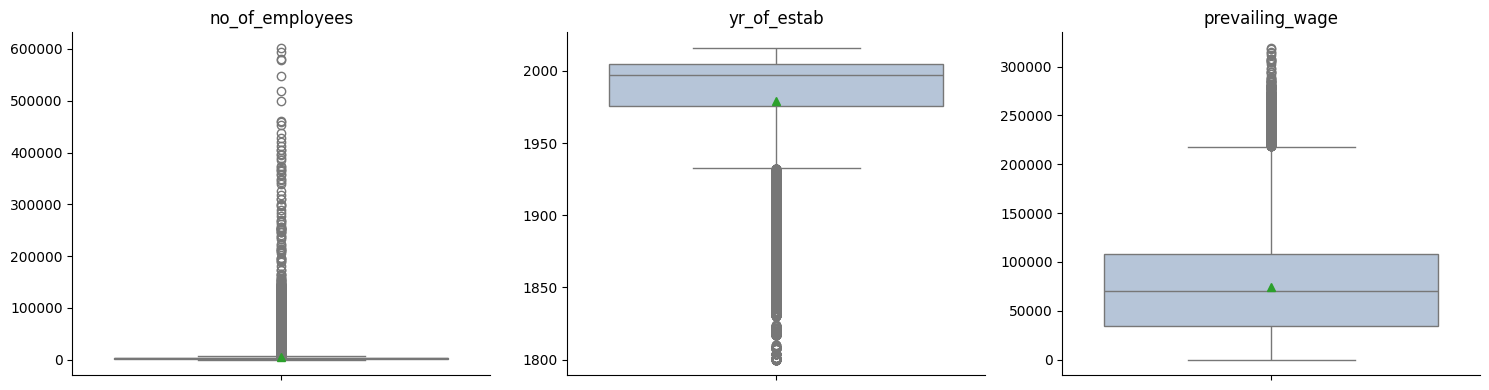

In [63]:
# Outlier detection using boxplots of the numerical variables
numeric_columns = data.select_dtypes(include=np.number).columns.tolist()

plt.figure(figsize=(15, 4))
for i, variable in enumerate(numeric_columns):
    plt.subplot(1, len(numeric_columns), i + 1)
    sns.boxplot(y=data[variable], showmeans=True, color="lightsteelblue")
    plt.title(variable, fontsize=12)
    plt.ylabel("")
sns.despine()
plt.tight_layout()
plt.show()

In [64]:
# Number and percentage of outliers in each numerical variable (IQR rule: outside Q1 - 1.5*IQR and Q3 + 1.5*IQR)
outlier_count, outlier_pct = {}, {}
for col in numeric_columns:
    q1, q3 = data[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    is_outlier = (data[col] < q1 - 1.5 * iqr) | (data[col] > q3 + 1.5 * iqr)
    outlier_count[col] = is_outlier.sum()
    outlier_pct[col] = round(is_outlier.mean() * 100, 2)

pd.DataFrame({"Outliers": outlier_count, "Percentage (%)": outlier_pct})

,Outliers,Percentage (%)
no_of_employees,1556,6.11
yr_of_estab,3260,12.79
prevailing_wage,427,1.68


##### **Observations:**
- no_of_employees has 1,556 outliers (6.1%), yr_of_estab 3,260 (12.8%) and prevailing_wage 427 (1.7%).
- I do not treat these outliers, because they are real values and not data entry errors: very large companies, old companies and highly paid positions.
- Removing them would lose information, and capping them would change real values.
- Decision Tree and Random Forest are not affected by outliers, and for Logistic Regression I will scale the data.
- The only data entry errors were the negative values in no_of_employees, which I already fixed in the EDA.

## Feature Engineering

##### **Observations:**
- I do not create new features:
  - Converting prevailing_wage to an annual value is not possible, because the analysis by unit of wage showed that the values do not match their units. Instead, I keep unit_of_wage as a feature.
  - A company age feature (e.g. 2016 - yr_of_estab) would carry the same information as yr_of_estab, so it would not add anything to the models.
- I already dropped case_id, because it is only an identifier.

## Data Preparation for Modeling

- I want to predict which visa applications will get certified.
- I encode the target and the categorical features.
- I split the data into training and test sets, so that I can evaluate the models on data they have not seen during training.
- Logistic Regression is affected by differences in the scale of the features, so I also scale the data for that model.

In [65]:
# Encoding the target variable: Certified = 1, Denied = 0
y = data["case_status"].apply(lambda x: 1 if x == "Certified" else 0)

# Separating the independent variables
X = data.drop(["case_status"], axis=1)

# Categorical features to encode (the numerical features are kept as they are)
categorical_features = X.select_dtypes("object").columns.tolist()
print(f"Categorical features to encode: {categorical_features}")

# Creating dummy variables (0/1) for the categorical features (drop_first to avoid redundant columns)
X = pd.get_dummies(X, columns=categorical_features, drop_first=True, dtype=int)

print(f"Number of features after encoding: {X.shape[1]}")
X.head()

Categorical features to encode: ['continent', 'education_of_employee', 'has_job_experience', 'requires_job_training', 'region_of_employment', 'unit_of_wage', 'full_time_position']
Number of features after encoding: 21


,no_of_employees,yr_of_estab,prevailing_wage,continent_Asia,continent_Europe,continent_North America,continent_Oceania,continent_South America,education_of_employee_Doctorate,education_of_employee_High School,education_of_employee_Master's,has_job_experience_Y,requires_job_training_Y,region_of_employment_Midwest,region_of_employment_Northeast,region_of_employment_South,region_of_employment_West,unit_of_wage_Month,unit_of_wage_Week,unit_of_wage_Year,full_time_position_Y
0,14513,2007,592.2029,1,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1
1,2412,2002,83425.6500,1,0,0,0,0,0,0,1,1,0,0,1,0,0,0,0,1,1
2,44444,2008,122996.8600,1,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,1,1
3,98,1897,83434.0300,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,1
4,1082,2005,149907.3900,0,0,0,0,0,0,0,1,1,0,0,0,1,0,0,0,1,1


In [66]:
# Splitting the data into training (70%) and test (30%) sets
# stratify=y keeps the same proportion of certified and denied applications in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=1, stratify=y
)

print(f"Shape of the training set: {X_train.shape}")
print(f"Shape of the test set:     {X_test.shape}")

print("\nPercentage of classes in the training set:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nPercentage of classes in the test set:")
print((y_test.value_counts(normalize=True) * 100).round(2))

Shape of the training set: (17836, 21)
Shape of the test set:     (7644, 21)

Percentage of classes in the training set:
case_status
1    66.79
0    33.21
Name: proportion, dtype: float64

Percentage of classes in the test set:
case_status
1    66.78
0    33.22
Name: proportion, dtype: float64


### Scaling the features

The numerical features have very different ranges: no_of_employees and prevailing_wage take much larger values than the dummy features (0/1).

I use StandardScaler (z-score: mean 0, standard deviation 1). I fit the scaler only on the training set and apply it to the test set, so that no information from the test set is used in training.

- `X_train_lr` and `X_test_lr` will be used for Logistic Regression.
- `X_train` and `X_test` (encoded but not scaled) will be used for Decision Tree and Random Forest, because tree-based models do not need scaling.

In [67]:
# Scaling the features for Logistic Regression (fit on the training set only)
sc = StandardScaler()

X_train_lr = pd.DataFrame(sc.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_lr = pd.DataFrame(sc.transform(X_test), columns=X_test.columns, index=X_test.index)

# Check: the scaled training features have mean 0 and standard deviation 1
X_train_lr[numeric_columns].describe().T[["mean", "std"]].round(2)

,mean,std
no_of_employees,-0.0,1.0
yr_of_estab,-0.0,1.0
prevailing_wage,0.0,1.0


##### **Observations:**
- I encoded the target as Certified = 1 and Denied = 0.
- After creating the dummy variables, the data has 21 features: 3 numerical and 18 dummies.
- The training set has 17,836 rows and the test set 7,644 rows (70% / 30%).
- Thanks to stratify, both sets keep the same proportion of classes as the original data (66.8% certified, 33.2% denied).
- After scaling, the numerical features of the training set have mean 0 and standard deviation 1.

# **Model Building: Logistic Regression, Decision Tree, and Random Forest**

## Model evaluation criterion

**The model can make wrong predictions in two ways** (Certified = 1 is the positive class):

1. **False positive:** the model predicts that the visa will be certified, but it should be denied.
2. **False negative:** the model predicts that the visa will be denied, but it should be certified.

**How will the model be used?**

I use the model as a **first filter**: it pre-selects the applications with a high chance of certification, and then an OFLC officer reviews only those pre-approved applications. The final decision is always made by a human, and the officer has fewer applications to review.

**Which case is more important?**

* A **false negative is the more costly error**. If the model wrongly marks a qualified applicant as Denied, that application is filtered out and nobody reviews it again. The US company loses a worker it needs to fill a real labor shortage, and EasyVisa fails its goal of facilitating visa approvals.
* A **false positive is less costly** in this process. If the model wrongly marks an application as Certified, the officer still reviews it and can deny it. The cost is extra review time, not a wrong certification.

**The other side:** from the point of view of OFLC, whose job is to protect US workers, a false positive is the more serious error, because a candidate who does not meet the requirements could take a job from a qualified US worker. This is why I do not let the model approve any application on its own: the human review after the first filter is what controls the false positives.

**Which metric should I use?**

* **Primary metric: F1-score.** I want to reduce false negatives, but I cannot use Recall alone: a model that predicts "Certified" for every application gets Recall = 1.0 without learning anything, and the officer would have to review every application again. F1 combines Recall and Precision, so it rewards a model that finds the certified applications without letting the false positives grow without control.
* **Secondary metric: Recall.** Since false negatives are the more costly error, I use Recall to break ties between models with a similar F1.
* I do not use Accuracy as the main metric because the target is imbalanced: a model that predicts "Certified" for every application would already have 66.8% accuracy.
* I handle the imbalance with stratify in the train-test split and with the choice of F1 as the primary metric. I do not resample the data because the imbalance is moderate (~2 to 1).
* I also report Accuracy and Precision to get a complete view of each model.

First, I create a function to show the classification report and the confusion matrix and to return the metrics, so that I do not repeat the same code for each model.

In [68]:
# function to print the classification report, plot the confusion matrix and return the metrics


def metrics_score(actual, predicted, title=""):
    """
    actual: true values of the target
    predicted: values predicted by the model
    title: title of the confusion matrix plot
    """
    print(classification_report(actual, predicted, target_names=["Denied", "Certified"]))

    # Confusion matrix with the count and the percentage of each cell
    cm = confusion_matrix(actual, predicted)
    labels = [[f"{value:,}\n({value / cm.sum() * 100:.1f}%)" for value in row] for row in cm]

    plt.figure(figsize=(6, 4.5))
    sns.heatmap(cm, annot=labels, fmt="", cmap="Greens", cbar=False, annot_kws={"size": 11},
                xticklabels=["Denied", "Certified"], yticklabels=["Denied", "Certified"])
    plt.title(title, fontsize=13)
    plt.xlabel("Predicted", fontsize=11)
    plt.ylabel("Actual", fontsize=11)
    plt.xticks(fontsize=10)
    plt.yticks(fontsize=10, rotation=0)
    plt.show()

    # Metrics for the positive class (Certified = 1)
    return {
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(actual, predicted),
        "Recall": recall_score(actual, predicted),
        "F1-Score": f1_score(actual, predicted),
    }

## Model Building - Logistic Regression

In [69]:
# Creating the Logistic Regression model
lg = LogisticRegression(random_state=1)

# Fitting the model on the scaled training data
lg.fit(X_train_lr, y_train)

LogisticRegression(random_state=1)

### Checking model performance on the training set

              precision    recall  f1-score   support

      Denied       0.65      0.46      0.54      5923
   Certified       0.76      0.88      0.82     11913

    accuracy                           0.74     17836
   macro avg       0.71      0.67      0.68     17836
weighted avg       0.73      0.74      0.73     17836



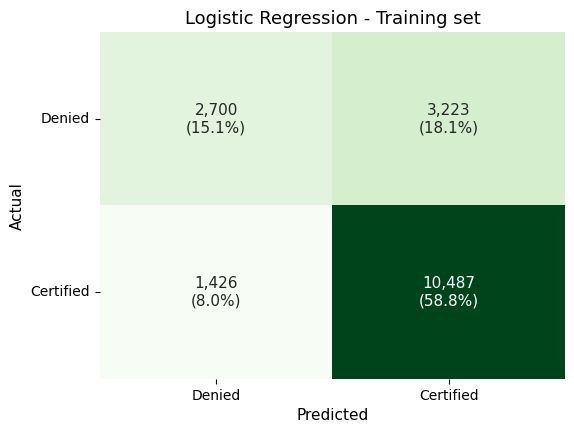

In [70]:
# Making predictions on the scaled training data
y_pred_train_lg = lg.predict(X_train_lr)

# Evaluating training performance
lg_train_metrics = metrics_score(y_train, y_pred_train_lg, title="Logistic Regression - Training set")

### Checking model performance on the test set

              precision    recall  f1-score   support

      Denied       0.65      0.45      0.53      2539
   Certified       0.76      0.88      0.82      5105

    accuracy                           0.74      7644
   macro avg       0.71      0.66      0.67      7644
weighted avg       0.73      0.74      0.72      7644



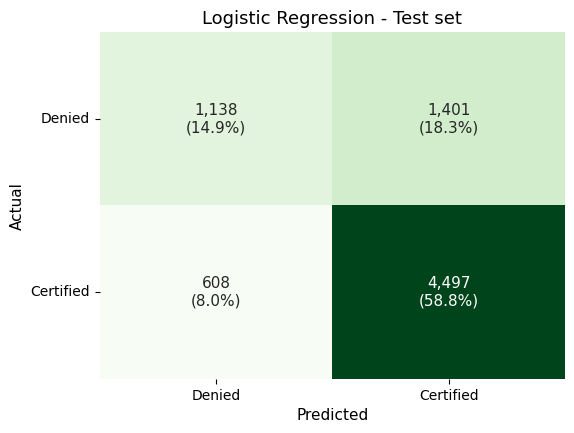

In [71]:
# Making predictions on the scaled test data
y_pred_test_lg = lg.predict(X_test_lr)

# Evaluating test performance
lg_test_metrics = metrics_score(y_test, y_pred_test_lg, title="Logistic Regression - Test set")

##### **Observations:**
- Logistic Regression has almost the same performance on the training set (F1 = 0.819) and the test set (F1 = 0.817). There is no overfitting: the model generalizes well.
- On the test set, it has a high Recall (0.881): it only misses 12% of the certified applications (608 of 5,105 are false negatives), which is the most costly error in this problem.
- Precision is lower (0.762) because the model only detects 45% of the denied applications (1,138 of 2,539), so the other 1,401 are false positives. In the process I propose this is acceptable, because the officer reviews every application pre-approved by the model and can deny them.

## Model Building - Decision Tree

In [72]:
# Creating the Decision Tree model
dt = DecisionTreeClassifier(random_state=1)

# Fitting the model on the encoded (not scaled) training data
dt.fit(X_train, y_train)

DecisionTreeClassifier(random_state=1)

### Checking model performance on the training set

              precision    recall  f1-score   support

      Denied       1.00      1.00      1.00      5923
   Certified       1.00      1.00      1.00     11913

    accuracy                           1.00     17836
   macro avg       1.00      1.00      1.00     17836
weighted avg       1.00      1.00      1.00     17836



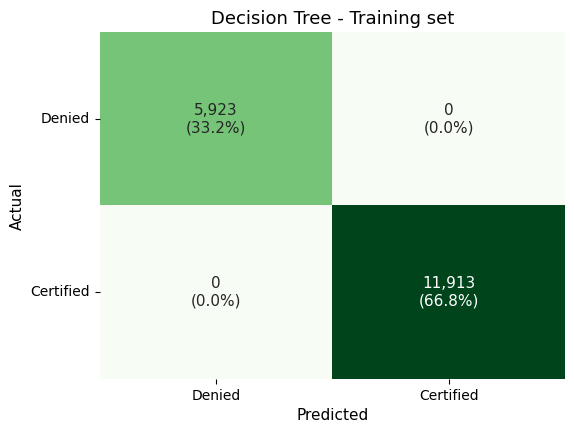

In [73]:
# Making predictions on the training data
y_pred_train_dt = dt.predict(X_train)

# Evaluating training performance
dt_train_metrics = metrics_score(y_train, y_pred_train_dt, title="Decision Tree - Training set")

### Checking model performance on the test set

              precision    recall  f1-score   support

      Denied       0.50      0.51      0.50      2539
   Certified       0.75      0.74      0.75      5105

    accuracy                           0.66      7644
   macro avg       0.62      0.63      0.62      7644
weighted avg       0.67      0.66      0.67      7644



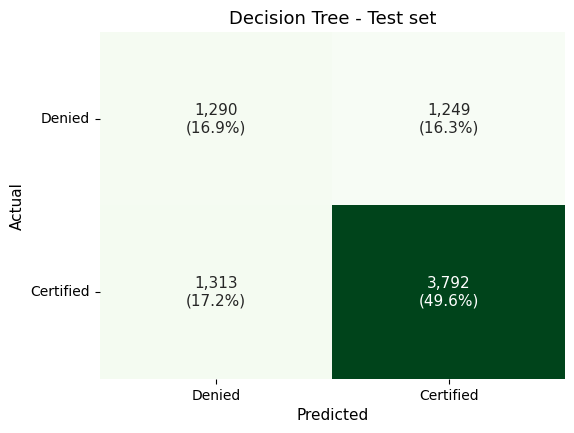

In [74]:
# Making predictions on the test data
y_pred_test_dt = dt.predict(X_test)

# Evaluating test performance
dt_test_metrics = metrics_score(y_test, y_pred_test_dt, title="Decision Tree - Test set")

##### **Observations:**
- The Decision Tree has a perfect performance on the training set (F1 = 1.0), but a much lower F1 on the test set (0.747). The gap of ~0.25 shows a strong overfitting.
- Without any limit, the tree grows until it memorizes the training data (depth 42 and 4,188 leaves), so it does not generalize to new applications.
- On the test set it has the lowest Accuracy (0.665) of the three models, and it makes many errors in both directions (1,249 false positives and 1,313 false negatives).

## Model Building - Random Forest

In [75]:
# Creating the Random Forest model
rf = RandomForestClassifier(random_state=1)

# Fitting the model on the encoded (not scaled) training data
rf.fit(X_train, y_train)

RandomForestClassifier(random_state=1)

### Checking model performance on the training set

              precision    recall  f1-score   support

      Denied       1.00      1.00      1.00      5923
   Certified       1.00      1.00      1.00     11913

    accuracy                           1.00     17836
   macro avg       1.00      1.00      1.00     17836
weighted avg       1.00      1.00      1.00     17836



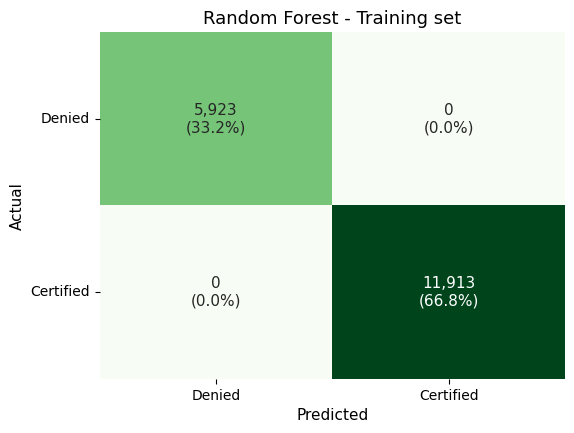

In [76]:
# Making predictions on the training data
y_pred_train_rf = rf.predict(X_train)

# Evaluating training performance
rf_train_metrics = metrics_score(y_train, y_pred_train_rf, title="Random Forest - Training set")

### Checking model performance on the test set

              precision    recall  f1-score   support

      Denied       0.60      0.50      0.55      2539
   Certified       0.77      0.83      0.80      5105

    accuracy                           0.72      7644
   macro avg       0.69      0.67      0.67      7644
weighted avg       0.71      0.72      0.72      7644



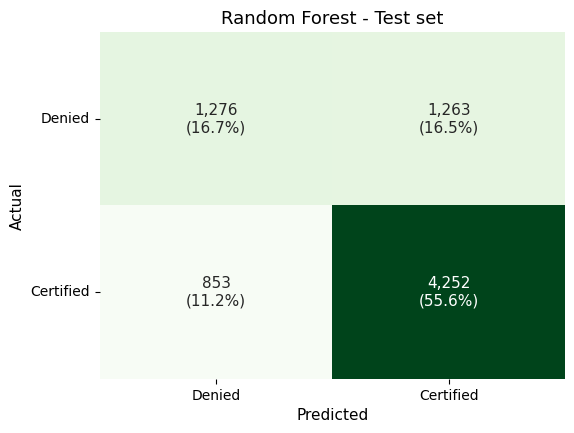

In [77]:
# Making predictions on the test data
y_pred_test_rf = rf.predict(X_test)

# Evaluating test performance
rf_test_metrics = metrics_score(y_test, y_pred_test_rf, title="Random Forest - Test set")

##### **Observations:**
- The Random Forest also has a perfect performance on the training set (F1 = 1.0) and a lower F1 on the test set (0.801), so it also overfits (gap of ~0.20).
- It overfits less than the Decision Tree and performs much better on the test set, because it averages many trees and reduces the variance of a single tree.
- On the test set, it has the highest Precision (0.771) of the three models, but a lower Recall (0.833) and F1 (0.801) than Logistic Regression.

# **Model Performance Comparison and Final Model Selection**

## Comparison of the three models

I compare the training and test performance of the three models on F1-score (primary metric), Recall (secondary metric), Accuracy and Precision.

In [78]:
# Collecting the training and test metrics of the three models
train_metrics = {"Logistic Regression": lg_train_metrics, "Decision Tree": dt_train_metrics, "Random Forest": rf_train_metrics}
test_metrics = {"Logistic Regression": lg_test_metrics, "Decision Tree": dt_test_metrics, "Random Forest": rf_test_metrics}

# Comparison table with the training and test metrics side by side
model_comparison = pd.concat(
    {"Train": pd.DataFrame(train_metrics).T, "Test": pd.DataFrame(test_metrics).T}, axis=1
).swaplevel(axis=1)[["F1-Score", "Recall", "Accuracy", "Precision"]]

# Generalization gap: training F1 minus test F1
model_comparison[("F1-Score", "Gap")] = model_comparison[("F1-Score", "Train")] - model_comparison[("F1-Score", "Test")]
model_comparison = model_comparison[["F1-Score", "Recall", "Accuracy", "Precision"]]

# Sorting by the primary metric (test F1) and then by the secondary metric (test Recall)
model_comparison.sort_values(by=[("F1-Score", "Test"), ("Recall", "Test")], ascending=False).round(3)

F1-Score               Recall        Accuracy         \
                       Train   Test    Gap  Train   Test    Train   Test   
Logistic Regression    0.819  0.817  0.001   0.88  0.881    0.739  0.737   
Random Forest          1.000  0.801  0.199   1.00  0.833    1.000  0.723   
Decision Tree          1.000  0.747  0.253   1.00  0.743    1.000  0.665   

                    Precision         
                        Train   Test  
Logistic Regression     0.765  0.762  
Random Forest           1.000  0.771  
Decision Tree           1.000  0.752

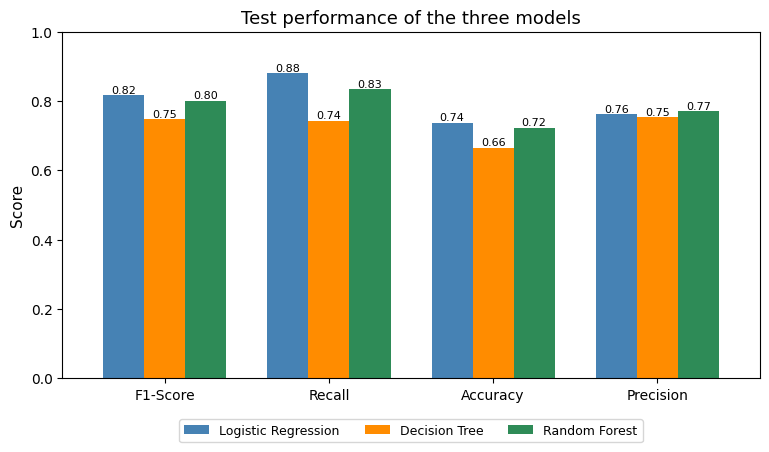

In [79]:
# Plotting the test metrics of the three models
test_comparison = pd.DataFrame(test_metrics).T[["F1-Score", "Recall", "Accuracy", "Precision"]]

ax = test_comparison.T.plot(kind="bar", figsize=(9, 4.5), color=["steelblue", "darkorange", "seagreen"], width=0.75)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=8)
plt.title("Test performance of the three models", fontsize=13)
plt.ylabel("Score", fontsize=11)
plt.ylim(0, 1)
plt.xticks(rotation=0, fontsize=10)
plt.legend(fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
plt.show()

##### **Observations:**
- **Logistic Regression is the best model on the test set** in the primary metric (F1 = 0.817) and in the secondary metric (Recall = 0.881). It also has the highest Accuracy (0.737).
- Random Forest is second (F1 = 0.801, Recall = 0.833). It has the highest Precision (0.771), but the difference with Logistic Regression is small (0.009).
- Decision Tree has the lowest test performance in all the metrics (F1 = 0.747).
- **The model that overfits the most is the Decision Tree**: perfect performance on the training set and the largest F1 gap (0.253). Random Forest also overfits (gap of 0.199).
- **The model that generalizes best is the Logistic Regression**: its training and test metrics are almost the same (F1 gap of 0.001).

## Final model selection

**I select Logistic Regression as the final model**, for these reasons:

- **Primary metric:** it has the highest F1-score on the test set (0.817), so it has the best balance between finding the certified applications and controlling the false positives.
- **Secondary metric:** it has the highest Recall (0.881), so it makes the fewest false negatives, which is the most costly error in this problem: 608 qualified applicants missed, compared with 853 for the Random Forest and 1,313 for the Decision Tree.
- **Generalization:** it has almost no gap between training and test (0.001), so I expect a similar performance on new applications. The two tree models memorize the training data.
- **Precision:** Random Forest has a slightly higher Precision (0.771 vs 0.762), but in my process every application pre-approved by the model is reviewed by an officer, so this small difference in false positives is an acceptable cost.
- **Interpretability:** its coefficients show which factors increase or decrease the chance of certification, which helps OFLC and EasyVisa to explain the decisions.

I built the three models with their default hyperparameters. Limiting the depth of the trees could reduce their overfitting, but this was outside the scope of this project.

### Final model performance on the test set

              precision    recall  f1-score   support

      Denied       0.65      0.45      0.53      2539
   Certified       0.76      0.88      0.82      5105

    accuracy                           0.74      7644
   macro avg       0.71      0.66      0.67      7644
weighted avg       0.73      0.74      0.72      7644



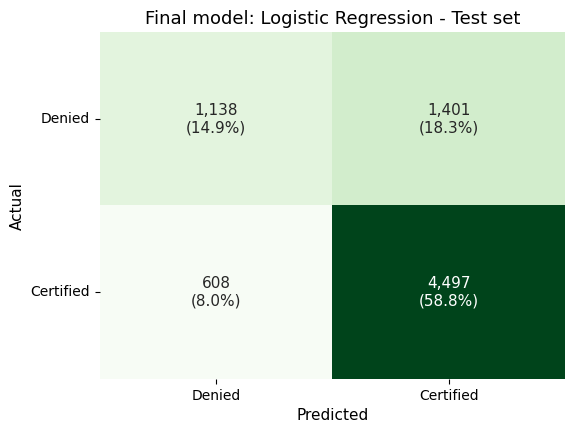

,Accuracy,Precision,Recall,F1-Score
Logistic Regression (test),0.737,0.762,0.881,0.817


In [80]:
# Test performance of the final model (Logistic Regression)
final_metrics = metrics_score(y_test, y_pred_test_lg, title="Final model: Logistic Regression - Test set")
pd.DataFrame(final_metrics, index=["Logistic Regression (test)"]).round(3)

##### **Observations:**
- On the test set, the final model has F1 = 0.817, Recall = 0.881, Precision = 0.762 and Accuracy = 0.737.
- As a first filter, the model pre-approves 5,898 of the 7,644 test applications (77%), so the officer reviews about 23% fewer applications. 4,497 of the pre-approved applications are really certified.
- The model misses 608 of the 5,105 certified applications (12%). These are the false negatives that the process does not recover.
- The model also stops 1,138 of the 2,539 denied applications (45%) before the human review. The other 1,401 denied applications reach the officer, who can deny them.

### Drivers of certification in the final model

Since the data is scaled, I can compare the coefficients of the Logistic Regression: a positive coefficient increases the chance of certification and a negative coefficient decreases it.

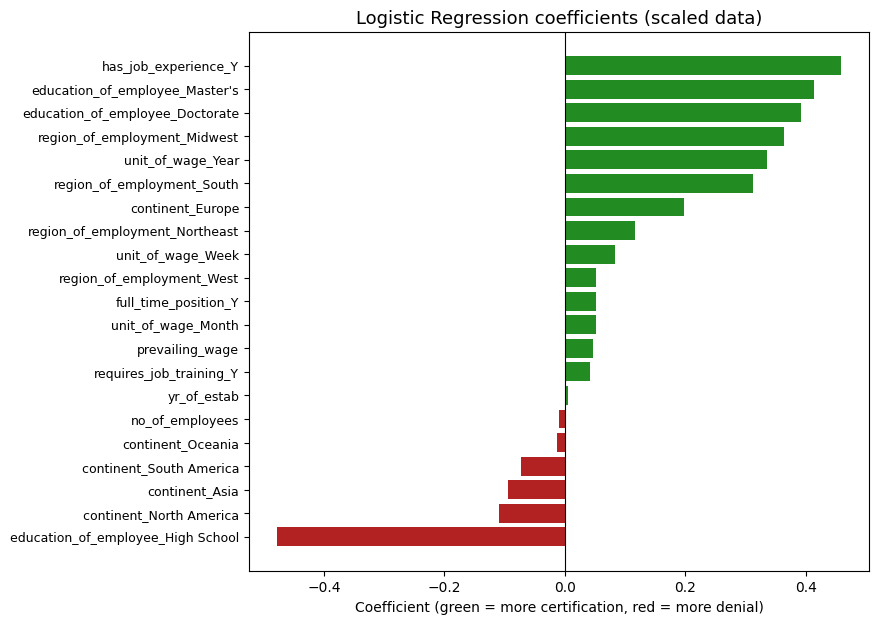

In [81]:
# Coefficients of the Logistic Regression, sorted from the most positive to the most negative
coefficients = pd.Series(lg.coef_[0], index=X_train.columns).sort_values()

plt.figure(figsize=(8, 7))
colors = ["forestgreen" if value > 0 else "firebrick" for value in coefficients]
plt.barh(coefficients.index, coefficients.values, color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Logistic Regression coefficients (scaled data)", fontsize=13)
plt.xlabel("Coefficient (green = more certification, red = more denial)", fontsize=10)
plt.yticks(fontsize=9)
plt.show()

##### **Observations:**
- The coefficients of the dummy variables are compared with the category that I dropped with `drop_first=True`: Bachelor's (education), Africa (continent), Island (region), Hour (unit of wage) and N (Y/N variables).
- **Factors that increase the chance of certification:** having job experience, a Master's or a Doctorate degree, working in the Midwest or the South, a yearly wage (instead of hourly) and coming from Europe.
- **Factors that decrease the chance of certification:** having only a High School education is the strongest negative factor. Coming from Asia, North America or South America also decreases it slightly.
- The numerical variables (`prevailing_wage`, `no_of_employees`, `yr_of_estab`), `requires_job_training` and `full_time_position` have coefficients close to zero, so they have little effect.
- These drivers match the patterns that I found in the EDA (education, job experience, region, unit of wage and continent).

### Distribution of the predicted probabilities

The Logistic Regression gives a probability of certification for each application, and it predicts Certified when this probability is 0.5 or higher. I plot these probabilities for the certified and the denied applications of the test set, to see how well the model separates the two classes and where the errors are.

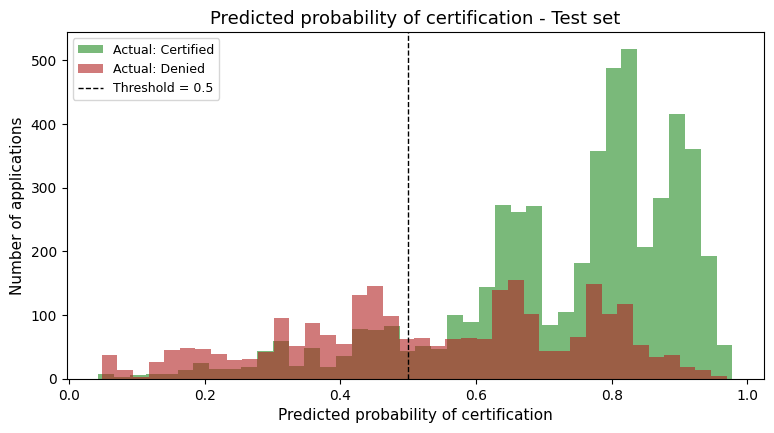

In [82]:
# Probability of certification predicted by the final model for the test set
prob_test_lg = lg.predict_proba(X_test_lr)[:, 1]

# Histogram of the predicted probabilities by actual class
plt.figure(figsize=(9, 4.5))
plt.hist(prob_test_lg[y_test == 1], bins=40, alpha=0.6, color="forestgreen", label="Actual: Certified")
plt.hist(prob_test_lg[y_test == 0], bins=40, alpha=0.6, color="firebrick", label="Actual: Denied")
plt.axvline(0.5, color="black", linestyle="--", linewidth=1, label="Threshold = 0.5")
plt.title("Predicted probability of certification - Test set", fontsize=13)
plt.xlabel("Predicted probability of certification", fontsize=11)
plt.ylabel("Number of applications", fontsize=11)
plt.legend(fontsize=9)
plt.show()

In [83]:
# Applications and real certification rate by range of predicted probability
probability_range = pd.cut(prob_test_lg, bins=[0, 0.3, 0.5, 0.7, 0.9, 1.0])
probability_table = y_test.groupby(probability_range, observed=True).agg(
    Applications="size",
    Certified_pct=lambda x: round(x.mean() * 100, 1),
)
probability_table.index.name = "Predicted probability"
probability_table.rename(columns={"Certified_pct": "Actually certified (%)"})

,Applications,Actually certified (%)
Predicted probability,,
"(0.0, 0.3]",520,31.2
"(0.3, 0.5]",1226,36.4
"(0.5, 0.7]",2007,63.1
"(0.7, 0.9]",3125,80.1
"(0.9, 1.0]",766,95.2


##### **Observations:**
- The certified applications are concentrated at high probabilities (0.6 to 0.95), but the denied applications are spread across the whole range. Many denied applications are above the 0.5 threshold, and these are the false positives.
- When the model is very confident, it is usually right: 95.2% of the applications with a probability above 0.9 are really certified, and 80.1% between 0.7 and 0.9.
- Between 0.5 and 0.7 only 63.1% are certified, which is almost the same as the overall rate (66.8%). In this zone the model is not really sure.
- Below 0.5 about one in three applications is still certified (31-36%). These are the 608 false negatives.
- So the probability is more useful than the Certified/Denied label alone: the officer can use it to prioritize the review (fast review above 0.9, careful review between 0.5 and 0.7).

### Error analysis

I check in which groups of applicants the final model makes more errors. For each group I calculate:
- **FN rate:** % of the certified applications that the model predicts as Denied (qualified applicants that the first filter misses).
- **FP rate:** % of the denied applications that the model predicts as Certified (applications that reach the officer and have to be denied).

In [84]:
# Test set with the original (not encoded) variables, the actual class and the prediction of the final model
errors = data.loc[X_test.index].copy()
errors["actual"] = y_test
errors["predicted"] = y_pred_test_lg


# function to calculate the FN rate and the FP rate for each category of a variable
def error_rates(df, variable):
    certified = df[df["actual"] == 1]
    denied = df[df["actual"] == 0]
    return pd.DataFrame({
        "Applications": df.groupby(variable).size(),
        "FN rate (%)": (certified["predicted"] == 0).groupby(certified[variable]).mean() * 100,
        "FP rate (%)": (denied["predicted"] == 1).groupby(denied[variable]).mean() * 100,
    }).round(1)


# Error rates for the variables with the largest effect in the model
error_table = pd.concat(
    {variable: error_rates(errors, variable) for variable in ["education_of_employee", "unit_of_wage", "has_job_experience"]}
)
error_table

Applications  FN rate (%)  FP rate (%)
education_of_employee Bachelor's           3099         14.5         56.9
                      Doctorate             623          0.0         94.3
                      High School          1002         81.6         14.6
                      Master's             2920          1.7         87.6
unit_of_wage          Hour                  648         62.9         19.1
                      Month                  20         33.3         75.0
                      Week                   80         12.0         86.7
                      Year                 6896          9.6         62.2
has_job_experience    N                    3209         23.8         42.5
                      Y                    4435          5.4         70.9

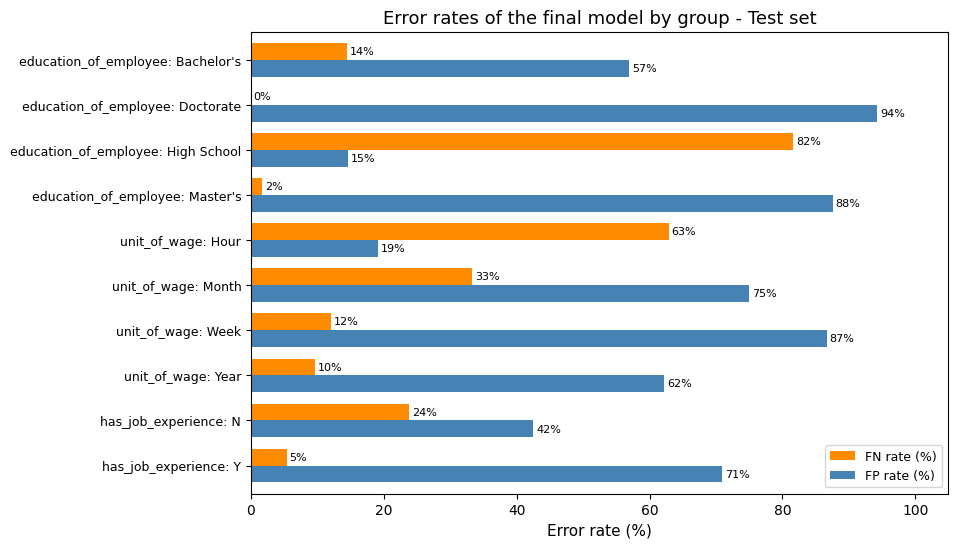

In [85]:
# Plotting the FN rate and the FP rate of each group
ax = error_table[["FN rate (%)", "FP rate (%)"]].plot(
    kind="barh", figsize=(9, 6), color=["darkorange", "steelblue"], width=0.75
)
ax.set_yticklabels([f"{variable}: {category}" for variable, category in error_table.index], fontsize=9)
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f%%", fontsize=8, padding=2)
ax.invert_yaxis()
plt.title("Error rates of the final model by group - Test set", fontsize=13)
plt.xlabel("Error rate (%)", fontsize=11)
plt.xlim(0, 105)
plt.legend(fontsize=9, loc="lower right")
plt.show()

##### **Observations:**
- The model relies heavily on education: it predicts Certified for almost every Master's and Doctorate applicant (FP rates of 88% and 94%), and Denied for almost every High School applicant.
- **The false negatives are concentrated in two groups:**
  - High School: the model misses 82% of the certified High School applicants. They are 13% of the test set, but 47% of the false negatives (288 of 608).
  - Hourly wage: the model misses 63% of the certified applications with an hourly wage (134 false negatives).
  - Together, applicants with a High School education or an hourly wage are 397 of the 608 false negatives (65%).
- Applicants without job experience also have a higher FN rate (24% vs 5%).
- The false positives are mostly Bachelor's and Master's applicants (1,224 of 1,401). The officer reviews them, so this is the less costly error.
- The groups with a monthly (20) or weekly (80) wage are very small, so their rates are not reliable.
- Since the false negative is the most costly error, the applications of High School or hourly wage applicants should not be discarded automatically when the model predicts Denied. They should also go to the human review, or use a lower threshold.

# **Actionable Insights and Recommendations**

## Key drivers of visa certification

Both the EDA and the coefficients of the final model point to the same factors:

1. **Education is the strongest driver.** The certification rate goes from 34.0% for High School to 62.2% for Bachelor's, 78.6% for Master's and 87.2% for Doctorate. In the model, High School is the strongest negative factor and Master's and Doctorate are among the strongest positive ones.
2. **Job experience.** Applicants with job experience are certified 74.5% of the time, compared with 56.1% without experience. It is the strongest positive factor in the model.
3. **Unit of wage.** Only 34.6% of the applications with an hourly wage are certified, compared with 69.9% of the yearly wages. What matters is the unit, not the amount of the wage.
4. **Region of employment.** The Midwest (75.5%) and the South (70.0%) have the highest rates. The Northeast, the West and Island are between 60% and 63%.
5. **Continent.** Europe has the highest rate (79.2%) and South America the lowest (57.9%).

**Factors with little or no effect:** company size, year of establishment, the amount of the prevailing wage, full-time position and job training. The EDA showed almost no difference in the certification rate, and the model gives them coefficients close to zero.

## Applicant profiles

**Profile likely to be certified:**
- Master's or Doctorate degree, with job experience and a yearly wage. 90.5% of these applicants are certified (6,529 applications, 26% of the data).
- The chance is even higher if the applicant comes from Europe and the job is in the Midwest or the South.

**Profile likely to be denied:**
- High School education with an hourly wage: only 24.8% are certified (395 applications).
- High School education without job experience: only 31.7% are certified (1,396 applications).
- The chance is lower if the applicant comes from South America or North America and the job is in the West, the Northeast or Island.

These are the most likely outcomes, not rules. Between one in four and one in three applicants with the "denied" profile are still certified, and this is exactly where the model makes most of its false negatives.

## Recommendations for OFLC and EasyVisa

1. **Use the model as a first filter, never as the final decision.** The model pre-selects the applications with a high chance of certification and an officer reviews them. On the test set this reduces the number of applications to review by about 23%, and every pre-approved application still goes through the human review, which controls the false positives.
2. **Prioritize the review with the predicted probability, not only the label.** Applications above 0.9 are certified 95% of the time and can follow a fast review. Applications between 0.5 and 0.7 are uncertain and need a careful review.
3. **Do not discard automatically the applications predicted as Denied, especially for High School and hourly wage applicants.** These two groups have 65% of the false negatives. A second look at them, or a lower threshold for these groups, would recover qualified applicants that the model misses.
4. **Focus the review effort on the factors that matter.** Education, job experience, unit of wage and region explain most of the decision. Company size, year of establishment or full-time position add little information.
5. **Improve the quality of the wage data.** Most hourly wages are above 100 USD per hour and some yearly wages are below 10,000, so the `prevailing_wage` is often not consistent with its unit. EasyVisa should validate the wage and its unit when the employer submits the application.
6. **Advise employers and applicants.** Employers can expect a faster approval for applicants with higher education and job experience. Applicants with a High School education or without job experience should document their skills and experience well, because their applications have a much lower certification rate.

## How the model supports the certification process going forward

- **Faster processing:** the model gives a probability of certification for every new application in seconds, so OFLC can sort the applications and review first the clearest cases.
- **Less workload:** the officers review fewer applications, and they spend more time on the uncertain cases (probability between 0.5 and 0.7) and on the groups where the model makes more errors.
- **Explainable decisions:** the Logistic Regression coefficients show why an application gets a high or a low probability, which helps to explain the decisions to the applicants and the employers.
- **Next steps:** I would retrain the model regularly with new applications, monitor the false negative rate by group (education and unit of wage), and test a different threshold or `class_weight="balanced"` to reduce the false negatives without increasing too much the review workload.

___